# Исследовательский анализ данных сервиса Яндекс Афиша

- Автор: Самат Исмагилов

## Описание проекта

Продуктовая команда сервиса Яндекс Афиша заметила изменение пользовательского спроса осенью 2024 года. Причины этого изменения неясны: это сезонный фактор, смена предпочтений аудитории или рост популярности определенных событий? Также требуется проверить гипотезы о различиях в поведении пользователей мобильных и стационарных устройств.

## Цели проекта

1.  Выявить инсайты об изменении пользовательских предпочтений и популярности событий осенью 2024 года.
2.  Проверить гипотезы о различиях в поведении пользователей мобильных и стационарных устройств.

## Задачи проекта

1.  **Загрузка и знакомство с данными.** Оценить объем, корректность и соответствие описанию.
2.  **Предобработка данных:**
    *   Проверить пропуски и дубликаты.
    *   Изучить категориальные и количественные значения, обработать выбросы.
    *   Преобразовать типы данных и снизить размерность.
    *   Создать новые признаки (`revenue_rub`, `one_ticket_revenue_rub`, `month`, `season`).
3.  **Исследовательский анализ:**
    *   Проанализировать распределение заказов по сегментам (тип мероприятия, устройство, возрастной рейтинг) и их сезонные изменения.
    *   Изучить осеннюю активность пользователей по дням и недельную цикличность.
    *   Выделить популярные события, регионы и партнеров.
4.  **Статистический анализ:**
    *   Проверить гипотезу о различии среднего количества заказов на пользователя mobile и desktop.
    *   Проверить гипотезу о различии среднего времени между заказами mobile и desktop.
5.  **Формулировка выводов и рекомендаций.**

## Описание данных

| Датасет | Описание | Размер |
|---|---|---|
| `final_tickets_orders_df.csv` | Информация о заказах билетов | 287 923 строки |
| `final_tickets_events_df.csv` | Информация о мероприятиях | 22 427 строк |
| `final_tickets_tenge_df.csv` | Курс казахстанского тенге к российскому рублю за 2024 год | 357 строк |

**Период данных:** с 1 июня по 31 октября 2024 года.

## Структура проекта

*   **Шаг 1.** Загрузка данных и знакомство с ними.
*   **Шаг 2.** Предобработка данных и подготовка к исследованию.
*   **Шаг 3.** Исследовательский анализ данных.
    *   3.1. Анализ распределения заказов по сегментам и их сезонные изменения.
    *   3.2. Осенняя активность пользователей.
    *   3.3. Популярные события и партнеры.
*   **Шаг 4.** Статистический анализ данных (проверка гипотез).
*   **Шаг 5.** Общий вывод и рекомендации.

## 1. Загрузка данных и знакомство с ними

#### Импорт библиотек и загрузка данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

try:
    orders = pd.read_csv('/datasets/final_tickets_orders_df.csv')
    events = pd.read_csv('/datasets/final_tickets_events_df.csv')
    tenge = pd.read_csv('/datasets/final_tickets_tenge_df.csv')
    print("Данные успешно загружены!")
except FileNotFoundError as e:
    print(f"Ошибка: Файл не найден. Проверьте путь. {e}")

Данные успешно загружены!


#### Первичный осмотр данных (Orders)

In [2]:
print(f"Размер датасета orders: {orders.shape}")
display(orders.head())

print("\nИнформация о датасете orders:")
orders.info()

Размер датасета orders: (290849, 14)


,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,Край билетов,4,10870.99,NaN
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,Мой билет,2,2067.51,NaN
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,За билетом!,4,13984.16,75.00
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,Лови билет!,2,212.28,NaN
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,Билеты без проблем,3,10695.43,83.00



Информация о датасете orders:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: fl

#### Первичный осмотр данных (Events)

In [3]:
print(f"Размер датасета events: {events.shape}")
display(events.head())

print("\nИнформация о датасете events:")
events.info()

Размер датасета events: (22427, 11)


,event_id,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
0,4436,e4f26fba-da77-4c61-928a-6c3e434d793f,спектакль,театр,№4893,Североярская область,Озёрск,2,1600,"Кладбище искусств ""Проблема"" и партнеры","наб. Загородная, д. 785"
1,5785,5cc08a60-fdea-4186-9bb2-bffc3603fb77,спектакль,театр,№1931,Светополянский округ,Глиноград,54,2196,"Лекции по искусству ""Свет"" Групп","ул. Ягодная, д. 942"
2,8817,8e379a89-3a10-4811-ba06-ec22ebebe989,спектакль,театр,№4896,Североярская область,Озёрск,2,4043,"Кинокомитет ""Золотая"" Инк","ш. Коммуны, д. 92 стр. 6"
3,8849,682e3129-6a32-4952-9d8a-ef7f60d4c247,спектакль,театр,№4960,Каменевский регион,Глиногорск,213,1987,"Выставка ремесел ""Свет"" Лтд","пер. Набережный, д. 35"
4,8850,d6e99176-c77f-4af0-9222-07c571f6c624,спектакль,театр,№4770,Лесодальний край,Родниковец,55,4230,"Фестивальный проект ""Листья"" Групп","пер. Проезжий, д. 9"



Информация о датасете events:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   event_id                22427 non-null  int64 
 1   event_name              22427 non-null  object
 2   event_type_description  22427 non-null  object
 3   event_type_main         22427 non-null  object
 4   organizers              22427 non-null  object
 5   region_name             22427 non-null  object
 6   city_name               22427 non-null  object
 7   city_id                 22427 non-null  int64 
 8   venue_id                22427 non-null  int64 
 9   venue_name              22427 non-null  object
 10  venue_address           22427 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.9+ MB


#### Первичный осмотр данных (Tenge)

In [4]:
print(f"Размер датасета tenge: {tenge.shape}")
display(tenge.head())

print("\nИнформация о датасете tenge:")
tenge.info()

Размер датасета tenge: (357, 4)


,data,nominal,curs,cdx
0,2024-01-10,100,19.94,kzt
1,2024-01-11,100,19.73,kzt
2,2024-01-12,100,19.58,kzt
3,2024-01-13,100,19.45,kzt
4,2024-01-14,100,19.45,kzt



Информация о датасете tenge:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB


### Промежуточный вывод

**1. Объем данных и структура:**
*   **`orders`:** 290 849 строк, 14 столбцов. Данные охватывают период с июня по октябрь 2024 года.
*   **`events`:** 22 427 строк, 11 столбцов. Содержит информацию о площадках, городах и типах событий.
*   **`tenge`:** 357 строк, 4 столбца. Содержит ежедневный курс тенге к рублю за 2024 год.

**2. Соответствие описанию:**
*   Структура таблиц полностью соответствует описанию в задании.
*   В `orders` присутствует столбец `days_since_prev`, и, как указано в задании, в нем есть пропуски.
*   В `orders` валюта представлена двумя значениями: `rub` и `kzt`.
*   В `events` исключены фильмы, данные содержат только театральные постановки, концерты и т.д.

**3. Типы данных:**
*   **Даты:** В `orders` столбцы `created_dt_msk` и `created_ts_msk`, а также `data` в `tenge` имеют тип `object`. **Необходима конвертация в `datetime`** для дальнейшего анализа сезонности и временных рядов.
*   **Числовые:** `revenue`, `total`, `tickets_count` — числовые типы, готовы к расчетам.
*   **Категориальные:** `currency_code`, `device_type_canonical`, `service_name` — строковые типы, требуют проверки на уникальность и возможной нормализации.

**4. План предобработки:**
1.  **Конвертация типов:** Преобразовать даты в `datetime`.
2.  **Обработка пропусков:** Проанализировать пропуски в `days_since_prev`.
3.  **Валюты:** Объединить `orders` с `tenge` по дате, чтобы перевести все суммы в рубли.
4.  **Feature Engineering:** Создать столбцы `month`, `season`, `one_ticket_revenue_rub`.
5.  **Выбросы:** Проверить `revenue` и `tickets_count` на наличие аномалий.
6.  **Дубликаты:** Проверить явные и неявные дубликаты заказов.

## 2. Предобработка данных и подготовка их к исследованию

#### Проверка пропусков в данных

In [5]:
print("Пропуски в orders")
orders_nulls = orders.isnull().sum()
display(orders_nulls[orders_nulls > 0])

print("\nПропуски в events")
events_nulls = events.isnull().sum()
display(events_nulls[events_nulls > 0])

print("\nПропуски в tenge")
tenge_nulls = tenge.isnull().sum()
display(tenge_nulls[tenge_nulls > 0])

print("\nПолная проверка orders на пропуски")
if orders.drop(columns=['days_since_prev']).isnull().sum().sum() == 0:
    print("Выгрузка из SQL успешна: в orders нет пропусков, кроме столбца days_since_prev.")
else:
    print("Внимание! Обнаружены пропуски в других столбцах orders:")
    print(orders.drop(columns=['days_since_prev']).isnull().sum()[orders.drop(columns=['days_since_prev']).isnull().sum() > 0])

Пропуски в orders


days_since_prev    21940
dtype: int64


Пропуски в events


Series([], dtype: int64)


Пропуски в tenge


Series([], dtype: int64)


Полная проверка orders на пропуски
Выгрузка из SQL успешна: в orders нет пропусков, кроме столбца days_since_prev.


Для категориальных значений изучите, какие категории присутствуют в данных. Проверьте, встречаются ли значения, которые могут обозначать пропуски в данных или отсутствие информации. Проведите нормализацию данных, если это необходимо.

#### Изучение категориальных значений

In [6]:
cat_columns_orders = ['currency_code', 'device_type_canonical', 'service_name', 'cinema_circuit']
cat_columns_events = ['event_type_main', 'event_type_description', 'region_name', 'city_name']

print("Уникальные значения в orders")
for col in cat_columns_orders:
    print(f"\n--- {col} ---")
    print(f"Количество уникальных: {orders[col].nunique()}")
    print(orders[col].value_counts(dropna=False).head(10))

print("\n\nУникальные значения в events")
for col in cat_columns_events:
    print(f"\n--- {col} ---")
    print(f"Количество уникальных: {events[col].nunique()}")
    print(events[col].value_counts(dropna=False).head(10))

Уникальные значения в orders

--- currency_code ---
Количество уникальных: 2
rub    285780
kzt      5069
Name: currency_code, dtype: int64

--- device_type_canonical ---
Количество уникальных: 2
mobile     232679
desktop     58170
Name: device_type_canonical, dtype: int64

--- service_name ---
Количество уникальных: 36
Билеты без проблем    63709
Лови билет!           41126
Билеты в руки         40364
Мой билет             34843
Облачко               26642
Лучшие билеты         17795
Весь в билетах        16849
Прачечная             10273
Край билетов           6207
Тебе билет!            5228
Name: service_name, dtype: int64

--- cinema_circuit ---
Количество уникальных: 6
нет           289451
Другое          1261
КиноСити         122
Москино            7
Киномакс           7
ЦентрФильм         1
Name: cinema_circuit, dtype: int64


Уникальные значения в events

--- event_type_main ---
Количество уникальных: 7
концерты    8680
театр       7076
другое      4658
спорт        872
стендап

#### Проверка на «мусорные» значения

In [7]:
suspicious_values = ['unknown', 'n/a', 'na', 'нет данных', 'неизвестно', '', ' ', 'NaN', 'nan']

print("Поиск подозрительных значений")

def check_suspicious(df, col_name):
    found = df[df[col_name].astype(str).str.lower().isin(suspicious_values)]
    if not found.empty:
        print(f"Найдены подозрительные значения в {col_name}:")
        print(found[col_name].value_counts())
    else:
        print(f"В {col_name} подозрительных значений не найдено.")

for col in cat_columns_orders:
    check_suspicious(orders, col)

for col in cat_columns_events:
    check_suspicious(events, col)

Поиск подозрительных значений
В currency_code подозрительных значений не найдено.
В device_type_canonical подозрительных значений не найдено.
В service_name подозрительных значений не найдено.
В cinema_circuit подозрительных значений не найдено.
В event_type_main подозрительных значений не найдено.
В event_type_description подозрительных значений не найдено.
В region_name подозрительных значений не найдено.
В city_name подозрительных значений не найдено.


#### Статистика и распределение по валютам


Анализ для валюты: RUB

--- Статистика по revenue ---


count   285780.00
mean       547.57
std        871.52
min        -90.76
25%        113.83
50%        346.10
75%        791.70
95%       1606.50
99%       2569.59
max      81174.54
Name: revenue, dtype: float64


--- Статистика по tickets_count ---


count   285780.00
mean         2.75
std          1.17
min          1.00
25%          2.00
50%          3.00
75%          4.00
95%          5.00
99%          6.00
max         57.00
Name: tickets_count, dtype: float64

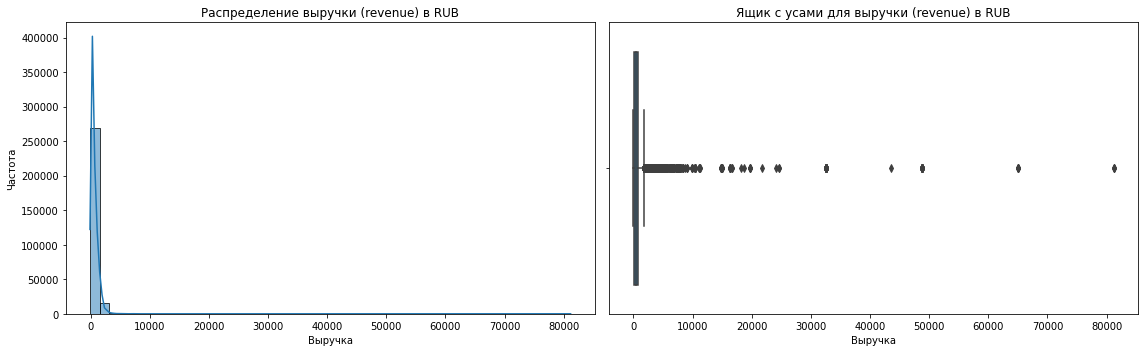

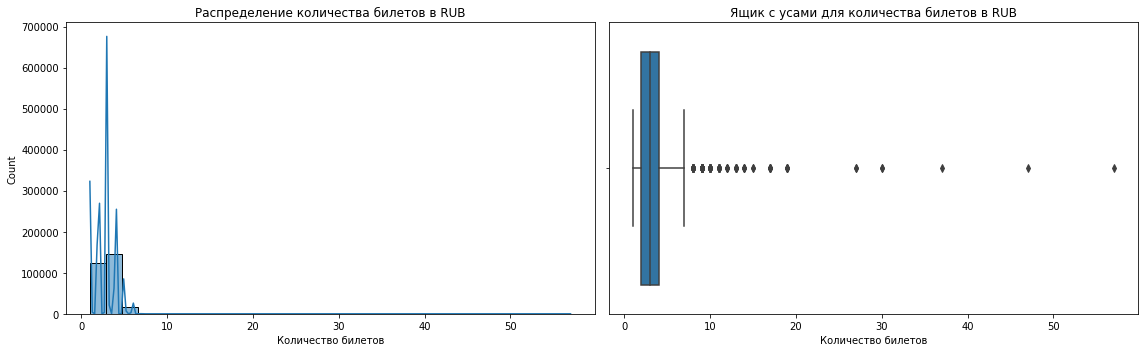


Анализ для валюты: KZT

--- Статистика по revenue ---


count    5069.00
mean     4995.21
std      4916.75
min         0.00
25%       518.10
50%      3698.83
75%      7397.66
95%     13784.26
99%     17617.24
max     26425.86
Name: revenue, dtype: float64


--- Статистика по tickets_count ---


count   5069.00
mean       2.76
std        1.12
min        1.00
25%        2.00
50%        3.00
75%        4.00
95%        5.00
99%        6.00
max        6.00
Name: tickets_count, dtype: float64

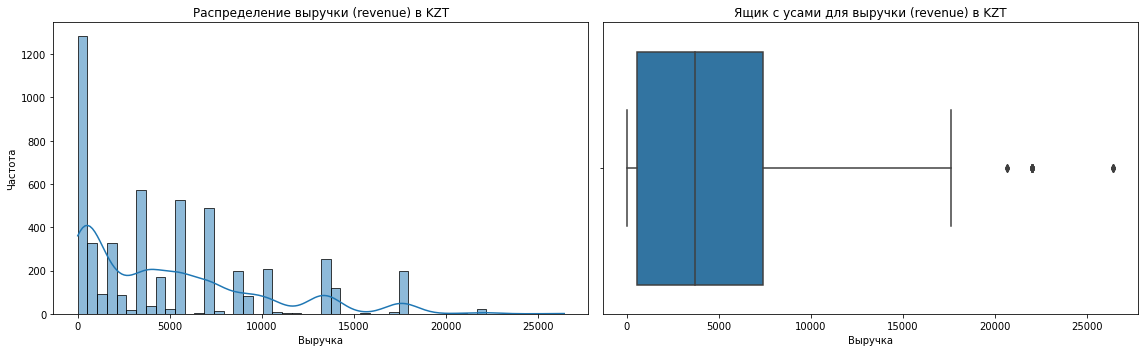

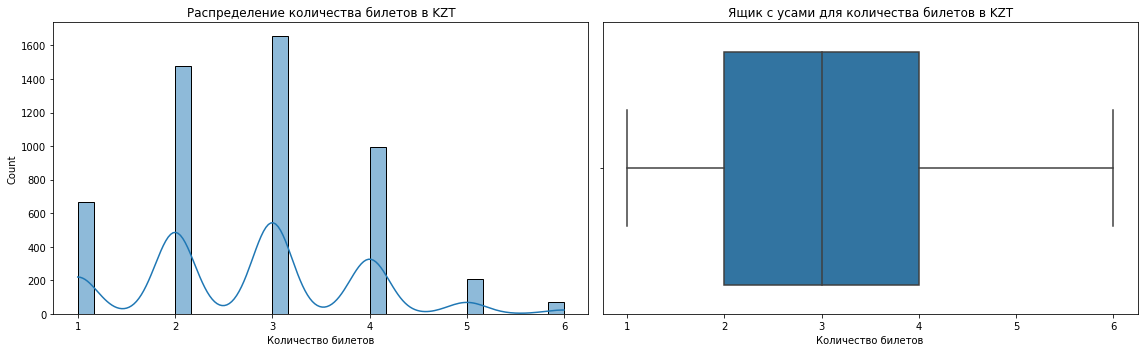

In [8]:
orders_rub = orders[orders['currency_code'] == 'rub']
orders_kzt = orders[orders['currency_code'] == 'kzt']

def analyze_quantitative(df, currency_name):
    print(f"\nАнализ для валюты: {currency_name}")
    
    print("\n--- Статистика по revenue ---")
    display(df['revenue'].describe(percentiles=[.25, .5, .75, .95, .99]))
    
    print("\n--- Статистика по tickets_count ---")
    display(df['tickets_count'].describe(percentiles=[.25, .5, .75, .95, .99]))
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    
    sns.histplot(df['revenue'], bins=50, ax=axes[0], kde=True)
    axes[0].set_title(f'Распределение выручки (revenue) в {currency_name}')
    axes[0].set_xlabel('Выручка')
    axes[0].set_ylabel('Частота')
    
    sns.boxplot(x=df['revenue'], ax=axes[1])
    axes[1].set_title(f'Ящик с усами для выручки (revenue) в {currency_name}')
    axes[1].set_xlabel('Выручка')
    
    plt.tight_layout()
    plt.show()
    

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    
    sns.histplot(df['tickets_count'], bins=30, ax=axes[0], kde=True)
    axes[0].set_title(f'Распределение количества билетов в {currency_name}')
    axes[0].set_xlabel('Количество билетов')
    
    sns.boxplot(x=df['tickets_count'], ax=axes[1])
    axes[1].set_title(f'Ящик с усами для количества билетов в {currency_name}')
    axes[1].set_xlabel('Количество билетов')
    
    plt.tight_layout()
    plt.show()

analyze_quantitative(orders_rub, 'RUB')
analyze_quantitative(orders_kzt, 'KZT')

#### Фильтрация выбросов по 99-му процентилю (для revenue)

In [9]:
q99_rub = orders_rub['revenue'].quantile(0.99)
q99_kzt = orders_kzt['revenue'].quantile(0.99)

print(f"99-й процентиль для RUB: {q99_rub:.2f}")
print(f"99-й процентиль для KZT: {q99_kzt:.2f}")

orders_rub_filtered = orders_rub[orders_rub['revenue'] <= q99_rub]
orders_kzt_filtered = orders_kzt[orders_kzt['revenue'] <= q99_kzt]

print(f"\nРазмер данных RUB до фильтрации: {len(orders_rub)}")
print(f"Размер данных RUB после фильтрации: {len(orders_rub_filtered)}")
print(f"Удалено строк (RUB): {len(orders_rub) - len(orders_rub_filtered)}")

print(f"\nРазмер данных KZT до фильтрации: {len(orders_kzt)}")
print(f"Размер данных KZT после фильтрации: {len(orders_kzt_filtered)}")
print(f"Удалено строк (KZT): {len(orders_kzt) - len(orders_kzt_filtered)}")

99-й процентиль для RUB: 2569.59
99-й процентиль для KZT: 17617.24

Размер данных RUB до фильтрации: 285780
Размер данных RUB после фильтрации: 282922
Удалено строк (RUB): 2858

Размер данных KZT до фильтрации: 5069
Размер данных KZT после фильтрации: 5040
Удалено строк (KZT): 29


#### Визуализация распределения после фильтрации

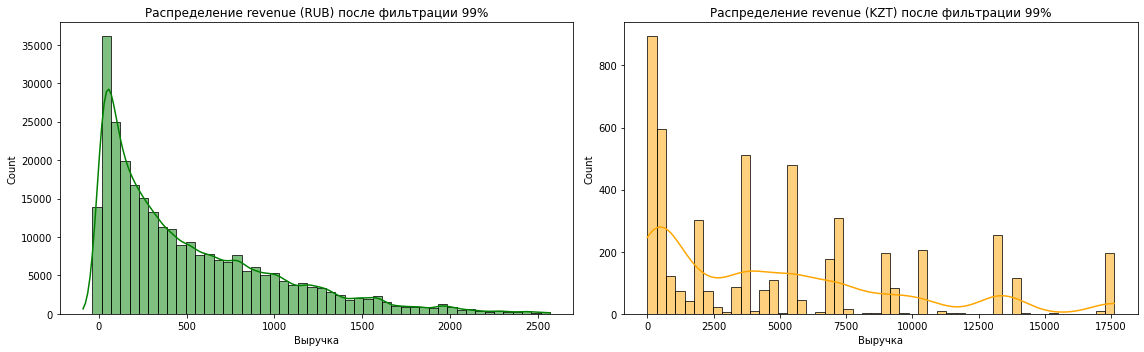

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(orders_rub_filtered['revenue'], bins=50, ax=axes[0], kde=True, color='green')
axes[0].set_title('Распределение revenue (RUB) после фильтрации 99%')
axes[0].set_xlabel('Выручка')

sns.histplot(orders_kzt_filtered['revenue'], bins=50, ax=axes[1], kde=True, color='orange')
axes[1].set_title('Распределение revenue (KZT) после фильтрации 99%')
axes[1].set_xlabel('Выручка')

plt.tight_layout()
plt.show()

#### Объединение отфильтрованных данных

In [11]:
orders = pd.concat([orders_rub_filtered, orders_kzt_filtered], ignore_index=True)

print(f"Размер orders после фильтрации: {orders.shape}")
print("\nРаспределение по валютам:")
print(orders['currency_code'].value_counts())

print("\nСтатистика revenue после фильтрации:")
display(orders.groupby('currency_code')['revenue'].describe(percentiles=[.25, .5, .75, .95, .99]))

Размер orders после фильтрации: (287962, 14)

Распределение по валютам:
rub    282922
kzt      5040
Name: currency_code, dtype: int64

Статистика revenue после фильтрации:


,count,mean,std,min,25%,50%,75%,95%,99%,max
currency_code,,,,,,,,,,
kzt,5040.00,4893.67,4742.68,0.00,515.35,3698.83,7397.66,13784.26,17617.24,17617.24
rub,282922.00,509.97,500.11,-90.76,111.66,340.25,781.09,1541.75,2091.31,2569.59


#### Проверка явных дубликатов

In [12]:
explicit_duplicates = orders.duplicated().sum()
print(f"Количество явных дубликатов (полных совпадений): {explicit_duplicates}")

if explicit_duplicates > 0:
    display(orders[orders.duplicated(keep=False)].sort_values(by=['user_id', 'created_ts_msk']).head(10))

Количество явных дубликатов (полных совпадений): 0


#### Проверка неявных дубликатов

In [13]:
dup_cols = ['user_id', 'event_id', 'created_ts_msk', 'revenue', 'tickets_count', 'service_name', 'device_type_canonical']

implicit_duplicates = orders.duplicated(subset=dup_cols, keep=False)
implicit_count = implicit_duplicates.sum()

print(f"Количество неявных дубликатов: {implicit_count}")

if implicit_count > 0:
    print("\nПримеры неявных дубликатов (первые 10 строк):")
    display(orders[implicit_duplicates].sort_values(by=['user_id', 'created_ts_msk']).head(10))

    print(f"\nКоличество уникальных групп неявных дубликатов: {orders[implicit_duplicates].groupby(dup_cols).ngroups}")

Количество неявных дубликатов: 75

Примеры неявных дубликатов (первые 10 строк):


,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
11496,1123983,06eb7897f65b433,2024-08-13,2024-08-13 16:31:07,183706,нет,18,rub,mobile,69.82,Билеты в руки,1,997.48,0.00
11497,1123867,06eb7897f65b433,2024-08-13,2024-08-13 16:31:07,183706,нет,18,rub,mobile,69.82,Билеты в руки,1,997.48,0.00
26355,1930705,0dc525d7bacbb0d,2024-07-31,2024-07-31 13:26:11,393430,нет,18,rub,desktop,1556.05,Лови билет!,3,19450.63,11.00
26357,1930763,0dc525d7bacbb0d,2024-07-31,2024-07-31 13:26:11,393430,нет,18,rub,desktop,1556.05,Лови билет!,3,19450.63,0.00
52458,1935113,206ea45ec11d478,2024-10-29,2024-10-29 16:46:54,442183,нет,16,rub,mobile,601.69,Билеты в руки,2,6016.94,32.00
52460,1935171,206ea45ec11d478,2024-10-29,2024-10-29 16:46:54,442183,нет,16,rub,mobile,601.69,Билеты в руки,2,6016.94,0.00
55833,160922,2564e3703075008,2024-10-30,2024-10-30 10:04:15,589005,нет,6,rub,mobile,11.23,Лови билет!,2,280.81,0.00
55836,160893,2564e3703075008,2024-10-30,2024-10-30 10:04:15,589005,нет,6,rub,mobile,11.23,Лови билет!,2,280.81,0.00
66545,3326185,2ecf0a4e24cae13,2024-10-17,2024-10-17 15:25:33,481392,нет,18,rub,mobile,40.33,Билеты без проблем,2,1008.14,7.00
66546,3326272,2ecf0a4e24cae13,2024-10-17,2024-10-17 15:25:33,481392,нет,18,rub,mobile,40.33,Билеты без проблем,2,1008.14,0.00



Количество уникальных групп неявных дубликатов: 36


#### Анализ неявных дубликатов

In [14]:
if implicit_count > 0:
    dup_cols = ['user_id', 'event_id', 'created_ts_msk', 'revenue', 'tickets_count', 'service_name', 'device_type_canonical']
    
    sample_group = orders[implicit_duplicates].groupby(dup_cols).filter(lambda x: len(x) > 1)
    
    first_group_key = sample_group.iloc[0][dup_cols].to_dict()
    print("Пример группы неявных дубликатов (полные данные):")
    display(orders[
        (orders['user_id'] == first_group_key['user_id']) &
        (orders['event_id'] == first_group_key['event_id']) &
        (orders['created_ts_msk'] == first_group_key['created_ts_msk'])
    ])
    
    print("\nРаспределение размеров групп неявных дубликатов:")
    group_sizes = sample_group.groupby(dup_cols).size()
    print(group_sizes.value_counts())
    
    print(f"\nВсего строк, затронутых неявными дубликатами: {len(sample_group)}")
    print(f"Из них 'лишних' строк (если оставить по 1 из группы): {len(sample_group) - group_sizes.nunique()}")
else:
    print("Неявных дубликатов не обнаружено.")

Пример группы неявных дубликатов (полные данные):


,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
11496,1123983,06eb7897f65b433,2024-08-13,2024-08-13 16:31:07,183706,нет,18,rub,mobile,69.82,Билеты в руки,1,997.48,0.00
11497,1123867,06eb7897f65b433,2024-08-13,2024-08-13 16:31:07,183706,нет,18,rub,mobile,69.82,Билеты в руки,1,997.48,0.00



Распределение размеров групп неявных дубликатов:
2    33
3     3
dtype: int64

Всего строк, затронутых неявными дубликатами: 75
Из них 'лишних' строк (если оставить по 1 из группы): 73


#### Удаление неявных дубликатов

In [15]:
dup_cols = ['user_id', 'event_id', 'created_ts_msk', 'revenue', 'tickets_count', 'service_name', 'device_type_canonical']

size_before = len(orders)

orders = orders.drop_duplicates(subset=dup_cols, keep='first').reset_index(drop=True)

size_after = len(orders)

print(f"Размер orders до удаления дубликатов: {size_before}")
print(f"Размер orders после удаления дубликатов: {size_after}")
print(f"Удалено строк: {size_before - size_after}")

remaining_duplicates = orders.duplicated(subset=dup_cols, keep=False).sum()
print(f"\nОсталось неявных дубликатов: {remaining_duplicates}")

Размер orders до удаления дубликатов: 287962
Размер orders после удаления дубликатов: 287923
Удалено строк: 39

Осталось неявных дубликатов: 0


#### Преобразование дат в формат datetime

In [16]:
orders['created_dt_msk'] = pd.to_datetime(orders['created_dt_msk'])
orders['created_ts_msk'] = pd.to_datetime(orders['created_ts_msk'])

tenge['data'] = pd.to_datetime(tenge['data'])

print("Типы после преобразования")
print("\norders:")
print(orders[['created_dt_msk', 'created_ts_msk']].dtypes)
print("\ntenge:")
print(tenge[['data']].dtypes)

print(f"\nДиапазон дат в orders: с {orders['created_dt_msk'].min()} по {orders['created_dt_msk'].max()}")
print(f"Диапазон дат в tenge: с {tenge['data'].min()} по {tenge['data'].max()}")

Типы после преобразования

orders:
created_dt_msk    datetime64[ns]
created_ts_msk    datetime64[ns]
dtype: object

tenge:
data    datetime64[ns]
dtype: object

Диапазон дат в orders: с 2024-06-01 00:00:00 по 2024-10-31 00:00:00
Диапазон дат в tenge: с 2024-01-10 00:00:00 по 2024-12-31 00:00:00


#### Снижение размерности количественных данных

In [17]:
print("Потребление памяти до оптимизации")
print(f"orders: {orders.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"events: {events.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"tenge: {tenge.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print("\nДиапазоны значений")
print(f"age_limit: min={orders['age_limit'].min()}, max={orders['age_limit'].max()}")
print(f"tickets_count: min={orders['tickets_count'].min()}, max={orders['tickets_count'].max()}")
print(f"days_since_prev: min={orders['days_since_prev'].min()}, max={orders['days_since_prev'].max()}")
print(f"nominal (tenge): min={tenge['nominal'].min()}, max={tenge['nominal'].max()}")

Потребление памяти до оптимизации
orders: 135.41 MB
events: 21.31 MB
tenge: 0.03 MB

Диапазоны значений
age_limit: min=0, max=18
tickets_count: min=1, max=57
days_since_prev: min=0.0, max=148.0
nominal (tenge): min=100, max=100


#### Оптимизация типов

In [18]:
orders['age_limit'] = orders['age_limit'].astype('int8')

orders['tickets_count'] = orders['tickets_count'].astype('int8')

orders['order_id'] = orders['order_id'].astype('int32')
orders['event_id'] = orders['event_id'].astype('int32')

events['event_id'] = events['event_id'].astype('int32')
events['city_id'] = events['city_id'].astype('int16')
events['venue_id'] = events['venue_id'].astype('int16')

tenge['nominal'] = tenge['nominal'].astype('int16')

print("Потребление памяти после оптимизации")
print(f"orders: {orders.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"events: {events.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"tenge: {tenge.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print("\nИтоговые типы в orders")
orders.info()

Потребление памяти после оптимизации
orders: 129.36 MB
events: 20.96 MB
tenge: 0.03 MB

Итоговые типы в orders
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 287923 entries, 0 to 287922
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   order_id               287923 non-null  int32         
 1   user_id                287923 non-null  object        
 2   created_dt_msk         287923 non-null  datetime64[ns]
 3   created_ts_msk         287923 non-null  datetime64[ns]
 4   event_id               287923 non-null  int32         
 5   cinema_circuit         287923 non-null  object        
 6   age_limit              287923 non-null  int8          
 7   currency_code          287923 non-null  object        
 8   device_type_canonical  287923 non-null  object        
 9   revenue                287923 non-null  float64       
 10  service_name           287923 non-null  object       

#### Подготовка курса валют и объединение с orders

In [19]:
print("Пример данных tenge:")
display(tenge.head(3))

tenge = tenge.rename(columns={'data': 'created_dt_msk'})

orders = orders.merge(
    tenge[['created_dt_msk', 'curs', 'nominal']], 
    on='created_dt_msk', 
    how='left'
)

print(f"\nПропуски в curs после merge: {orders['curs'].isnull().sum()}")
print(f"Всего строк в orders: {len(orders)}")

display(orders[['created_dt_msk', 'currency_code', 'revenue', 'curs', 'nominal']].head())

Пример данных tenge:


,data,nominal,curs,cdx
0,2024-01-10,100,19.94,kzt
1,2024-01-11,100,19.73,kzt
2,2024-01-12,100,19.58,kzt



Пропуски в curs после merge: 0
Всего строк в orders: 287923


,created_dt_msk,currency_code,revenue,curs,nominal
0,2024-08-20,rub,1521.94,18.70,100
1,2024-07-23,rub,289.45,18.34,100
2,2024-10-06,rub,1258.57,19.65,100
3,2024-07-13,rub,8.49,18.50,100
4,2024-10-04,rub,1390.41,19.66,100


#### Создание столбца revenue_rub

In [20]:
orders['revenue_rub'] = np.where(
    orders['currency_code'] == 'rub',
    orders['revenue'],
    orders['revenue'] * (orders['curs'] / orders['nominal'])
)

print("Проверка revenue_rub")
print("\nПримеры для RUB:")
display(orders[orders['currency_code'] == 'rub'][['revenue', 'currency_code', 'revenue_rub']].head(3))

print("\nПримеры для KZT:")
display(orders[orders['currency_code'] == 'kzt'][['revenue', 'currency_code', 'curs', 'nominal', 'revenue_rub']].head(3))

print("\nСтатистика revenue по валютам:")
display(orders.groupby('currency_code')['revenue'].describe()[['mean', '50%', 'max']])

print("\nСтатистика revenue_rub (все в рублях):")
display(orders['revenue_rub'].describe())

print(f"\nПропуски в revenue_rub: {orders['revenue_rub'].isnull().sum()}")

Проверка revenue_rub

Примеры для RUB:


,revenue,currency_code,revenue_rub
0,1521.94,rub,1521.94
1,289.45,rub,289.45
2,1258.57,rub,1258.57



Примеры для KZT:


,revenue,currency_code,curs,nominal,revenue_rub
282884,518.10,kzt,19.01,100,98.50
282885,347.18,kzt,18.93,100,65.73
282886,328.77,kzt,18.60,100,61.15



Статистика revenue по валютам:


,mean,50%,max
currency_code,,,
kzt,4894.27,3698.83,17617.24
rub,509.98,340.25,2569.59



Статистика revenue_rub (все в рублях):


count   287923.00
mean       517.88
std        514.51
min        -90.76
25%        111.38
50%        343.45
75%        787.93
max       3504.56
Name: revenue_rub, dtype: float64


Пропуски в revenue_rub: 0


#### Создание столбца one_ticket_revenue_rub

In [21]:
orders['one_ticket_revenue_rub'] = orders['revenue_rub'] / orders['tickets_count']

print("Статистика one_ticket_revenue_rub")
display(orders['one_ticket_revenue_rub'].describe(percentiles=[.25, .5, .75, .95, .99]))

print(f"\nПропуски: {orders['one_ticket_revenue_rub'].isnull().sum()}")
print(f"Минимальное значение: {orders['one_ticket_revenue_rub'].min()}")

negative_check = orders[orders['one_ticket_revenue_rub'] < 0]
print(f"\nЗаказов с отрицательной выручкой за билет: {len(negative_check)}")
if len(negative_check) > 0:
    display(negative_check[['order_id', 'revenue', 'tickets_count', 'one_ticket_revenue_rub']].head())

Статистика one_ticket_revenue_rub


count   287923.00
mean       190.78
std        168.25
min        -18.15
25%         45.70
50%        145.76
75%        305.33
95%        492.58
99%        680.70
max       2438.27
Name: one_ticket_revenue_rub, dtype: float64


Пропуски: 0
Минимальное значение: -18.152

Заказов с отрицательной выручкой за билет: 381


,order_id,revenue,tickets_count,one_ticket_revenue_rub
258,1594653,-2.37,3,-0.79
4461,2360920,-0.23,3,-0.08
4479,2361094,-0.15,2,-0.07
7991,166809,-0.62,1,-0.62
7992,166780,-1.86,3,-0.62


#### Создание столбцов month и season

In [22]:
orders['month'] = orders['created_dt_msk'].dt.month

def get_season(month):
    if month in [12, 1, 2]:
        return 'зима'
    elif month in [3, 4, 5]:
        return 'весна'
    elif month in [6, 7, 8]:
        return 'лето'
    else: 
        return 'осень'

orders['season'] = orders['month'].apply(get_season)

print("Распределение по месяцам")
print(orders['month'].value_counts().sort_index())

print("\nРаспределение по сезонам")
print(orders['season'].value_counts())

print("\nПримеры данных:")
display(orders[['created_dt_msk', 'month', 'season', 'revenue_rub', 'one_ticket_revenue_rub']].head())

Распределение по месяцам
6     34343
7     40408
8     44570
9     69331
10    99271
Name: month, dtype: int64

Распределение по сезонам
осень    168602
лето     119321
Name: season, dtype: int64

Примеры данных:


,created_dt_msk,month,season,revenue_rub,one_ticket_revenue_rub
0,2024-08-20,8,лето,1521.94,380.49
1,2024-07-23,7,лето,289.45,144.72
2,2024-10-06,10,осень,1258.57,314.64
3,2024-07-13,7,лето,8.49,4.25
4,2024-10-04,10,осень,1390.41,463.47


#### Финальная проверка 

In [23]:
print("Итоговая структура orders")
orders.info()

print(f"\nРазмер orders: {orders.shape}")
print(f"\nВсего пропусков: {orders.isnull().sum().sum()}")

orders = orders.drop(columns=['curs', 'nominal'])

print(f"\nРазмер orders после удаления временных столбцов: {orders.shape}")

Итоговая структура orders
<class 'pandas.core.frame.DataFrame'>
Int64Index: 287923 entries, 0 to 287922
Data columns (total 20 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   order_id                287923 non-null  int32         
 1   user_id                 287923 non-null  object        
 2   created_dt_msk          287923 non-null  datetime64[ns]
 3   created_ts_msk          287923 non-null  datetime64[ns]
 4   event_id                287923 non-null  int32         
 5   cinema_circuit          287923 non-null  object        
 6   age_limit               287923 non-null  int8          
 7   currency_code           287923 non-null  object        
 8   device_type_canonical   287923 non-null  object        
 9   revenue                 287923 non-null  float64       
 10  service_name            287923 non-null  object        
 11  tickets_count           287923 non-null  int8          
 12  tota

#### Анализ отрицательной выручки и решение

In [24]:
negative_orders = orders[orders['revenue'] < 0]
print(f"Количество заказов с revenue < 0: {len(negative_orders)}")
print(f"Доля от всех заказов: {len(negative_orders) / len(orders) * 100:.3f}%")

print("\nСтатистика по отрицательной выручке:")
display(negative_orders['revenue'].describe())

print("\nРаспределение отрицательных заказов по валютам:")
print(negative_orders['currency_code'].value_counts())

print("\nРаспределение отрицательных заказов по устройствам:")
print(negative_orders['device_type_canonical'].value_counts())

print("\nПримеры отрицательных заказов:")
display(negative_orders[['order_id', 'user_id', 'created_dt_msk', 'event_id', 'revenue', 'tickets_count', 'total', 'service_name']].head(10))

Количество заказов с revenue < 0: 381
Доля от всех заказов: 0.132%

Статистика по отрицательной выручке:


count   381.00
mean     -2.49
std       5.07
min     -90.76
25%      -3.45
50%      -1.58
75%      -0.65
max      -0.01
Name: revenue, dtype: float64


Распределение отрицательных заказов по валютам:
rub    381
Name: currency_code, dtype: int64

Распределение отрицательных заказов по устройствам:
mobile     358
desktop     23
Name: device_type_canonical, dtype: int64

Примеры отрицательных заказов:


,order_id,user_id,created_dt_msk,event_id,revenue,tickets_count,total,service_name
258,1594653,00eb3dc9baa1543,2024-06-29,538650,-2.37,3,-59.20,Билеты без проблем
4461,2360920,02ea4583333f064,2024-09-03,559772,-0.23,3,-7.65,Билеты без проблем
4479,2361094,02ea4583333f064,2024-09-04,559772,-0.15,2,-5.10,Билеты без проблем
7991,166809,043f669c9f734b1,2024-09-27,567183,-0.62,1,-20.64,Лучшие билеты
7992,166780,043f669c9f734b1,2024-09-27,567183,-1.86,3,-61.92,Лучшие билеты
11111,6620527,06727636bf2f465,2024-06-30,538650,-1.58,2,-39.46,Билеты без проблем
11112,6620498,06727636bf2f465,2024-07-01,538648,-1.58,2,-52.50,Билеты без проблем
11322,8333963,067494310c6617f,2024-10-07,569499,-6.18,4,-68.72,Билеты в руки
11374,8350029,067494310c6617f,2024-10-24,568916,-10.77,3,-215.31,Билеты в руки
11375,4930755,067494310c6617f,2024-10-24,568916,-3.59,1,-71.77,Билеты в руки


#### Обработка пропусков в days_since_prev и решение по отрицательным заказам

In [25]:
orders['days_since_prev'] = orders['days_since_prev'].fillna(0)

print(f"Пропуски в days_since_prev после заполнения: {orders['days_since_prev'].isnull().sum()}")

orders_positive = orders[orders['revenue'] > 0].copy()

print(f"\nРазмер orders (все заказы): {len(orders)}")
print(f"Размер orders_positive (без отрицательных): {len(orders_positive)}")
print(f"Удалено строк: {len(orders) - len(orders_positive)}")

Пропуски в days_since_prev после заполнения: 0

Размер orders (все заказы): 287923
Размер orders_positive (без отрицательных): 281806
Удалено строк: 6117


#### Исправление логики создания orders_positive

In [26]:
orders_positive = orders[orders['revenue'] >= 0].copy()

print(f"Размер orders (все заказы): {len(orders)}")
print(f"Размер orders_positive (без отрицательных): {len(orders_positive)}")
print(f"Удалено строк (только отрицательные): {len(orders) - len(orders_positive)}")

zero_check = orders_positive[orders_positive['revenue'] == 0]
print(f"\nЗаказов с revenue == 0 в orders_positive: {len(zero_check)}")

print("\nСтатистика one_ticket_revenue_rub в orders_positive")
display(orders_positive['one_ticket_revenue_rub'].describe(percentiles=[.25, .5, .75, .95, .99]))

Размер orders (все заказы): 287923
Размер orders_positive (без отрицательных): 287542
Удалено строк (только отрицательные): 381

Заказов с revenue == 0 в orders_positive: 5736

Статистика one_ticket_revenue_rub в orders_positive


count   287542.00
mean       191.03
std        168.22
min          0.00
25%         46.04
50%        146.13
75%        306.33
95%        492.58
99%        680.70
max       2438.27
Name: one_ticket_revenue_rub, dtype: float64

### Промежуточный вывод

**1. Обработка пропусков и дубликатов:**
*   Выгрузка из SQL прошла успешно: пропуски обнаружены только в `days_since_prev`.
*   Явных дубликатов не найдено. Обнаружено 36 групп неявных дубликатов, которые удалены как техническая ошибка — потеря составила 39 строк.
*   Пропуски в `days_since_prev` заполнены нулем.

**2. Проверка категориальных и количественных значений:**
*   В категориальных столбцах «мусорных» значений не обнаружено. Преобладают заказы в рублях и с мобильных устройств.
*   В `revenue` обнаружены значительные выбросы. Для каждой валюты проведена фильтрация по **99-му процентилю**.

**3. Преобразование типов данных:**
*   Даты переведены в `datetime64[ns]`.
*   Снижена размерность количественных столбцов: `age_limit`, `tickets_count` → `int8`; `order_id`, `event_id` → `int32` и т.д. Это уменьшило потребление памяти с 135 MB до 129 MB.

**4. Создание новых признаков:**
*   `revenue_rub` — выручка, приведенная к рублю.
*   `one_ticket_revenue_rub` — выручка с одного билета.
*   `month`, `season` — месяц и сезон оформления заказа.

**5. Работа с аномалиями:**
*   Обнаружен 381 заказ с отрицательной выручкой — это **возвраты билетов**. Их доля — 0.132%.
*   Для анализа среднего чека создан датафрейм `orders_positive`, где исключены только отрицательные значения. Заказы с нулевой выручкой оставлены, так как представляют реальный интерес.

**Итоговые датафреймы:**
| Датафрейм | Размер | Назначение |
|---|---|---|
| `orders` | 287 923 строки | Полный набор |
| `orders_positive` | 287 542 строки | Для анализа среднего чека и популярности |

**Вывод:** Данные полностью подготовлены к исследовательскому анализу.

## 3. Исследовательский анализ данных

#### Количество заказов по месяцам

In [27]:
monthly_orders = orders.groupby('month').agg(
    orders_count=('order_id', 'count')
).reset_index()

month_names = {
    6: 'Июнь', 7: 'Июль', 8: 'Август', 9: 'Сентябрь', 10: 'Октябрь'
}
monthly_orders['month_name'] = monthly_orders['month'].map(month_names)

print("Количество заказов по месяцам")
display(monthly_orders[['month', 'month_name', 'orders_count']])

monthly_orders['growth_%'] = monthly_orders['orders_count'].pct_change() * 100
print("\nПрирост заказов относительно предыдущего месяца")
display(monthly_orders[['month_name', 'orders_count', 'growth_%']])

Количество заказов по месяцам


,month,month_name,orders_count
0,6,Июнь,34343
1,7,Июль,40408
2,8,Август,44570
3,9,Сентябрь,69331
4,10,Октябрь,99271



Прирост заказов относительно предыдущего месяца


,month_name,orders_count,growth_%
0,Июнь,34343,NaN
1,Июль,40408,17.66
2,Август,44570,10.30
3,Сентябрь,69331,55.56
4,Октябрь,99271,43.18


#### Визуализация динамики заказов по месяцам

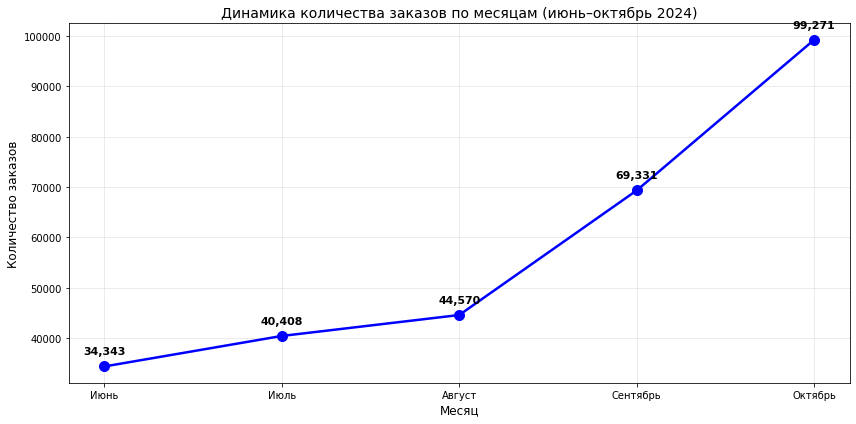

In [28]:
plt.figure(figsize=(12, 6))

plt.plot(monthly_orders['month_name'], monthly_orders['orders_count'], 
         marker='o', linewidth=2.5, markersize=10, color='blue')

for i, row in monthly_orders.iterrows():
    plt.annotate(f"{row['orders_count']:,}", 
                 (row['month_name'], row['orders_count']),
                 textcoords="offset points", xytext=(0, 12), 
                 ha='center', fontsize=11, fontweight='bold')

plt.title('Динамика количества заказов по месяцам (июнь–октябрь 2024)', fontsize=14)
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Количество заказов', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Столбчатая диаграмма 

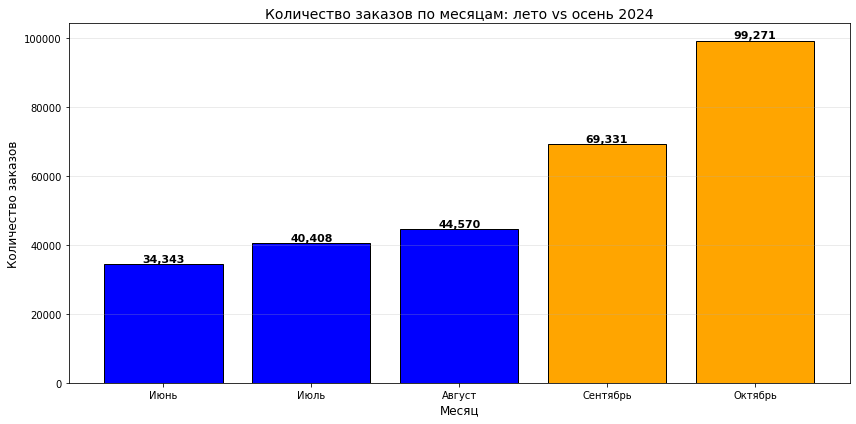

In [29]:
plt.figure(figsize=(12, 6))

colors = ['blue', 'blue', 'blue', 'orange', 'orange']  
bars = plt.bar(monthly_orders['month_name'], monthly_orders['orders_count'], color=colors, edgecolor='black')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height):,}',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.title('Количество заказов по месяцам: лето vs осень 2024', fontsize=14)
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Количество заказов', fontsize=12)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

#### Объединение orders с events и агрегация по сезонам

In [30]:
orders_full = orders.merge(
    events[['event_id', 'event_type_main']], 
    on='event_id', 
    how='left'
)

print(f"Размер orders_full: {orders_full.shape}")
print(f"Пропуски в event_type_main после merge: {orders_full['event_type_main'].isnull().sum()}")

orders_seasons = orders_full[orders_full['season'].isin(['лето', 'осень'])].copy()

print(f"\nРаспределение по сезонам:")
print(orders_seasons['season'].value_counts())

Размер orders_full: (287923, 19)
Пропуски в event_type_main после merge: 238

Распределение по сезонам:
осень    168602
лето     119321
Name: season, dtype: int64


#### Функция для расчета долей по категориям

In [31]:
def season_share(df, cat_column, season_col='season'):
    """
    Считает долю каждой категории внутри каждого сезона.
    Возвращает датафрейм в формате: season | category | count | share
    """
    result = df.groupby([season_col, cat_column]).agg(
        count=('order_id', 'count')
    ).reset_index()
    
    totals = df.groupby(season_col)['order_id'].count().reset_index()
    totals.columns = [season_col, 'total']
    
    result = result.merge(totals, on=season_col)
    result['share'] = (result['count'] / result['total'] * 100).round(2)
    
    return result

#### Распределение по типу мероприятия

Доли заказов по типу мероприятия (в %)


season,лето,осень
event_type_main,,
концерты,42.54,37.18
театр,20.07,25.35
другое,27.13,19.71
спорт,2.52,11.20
стендап,5.32,4.11
выставки,2.02,1.44
ёлки,0.23,1.00


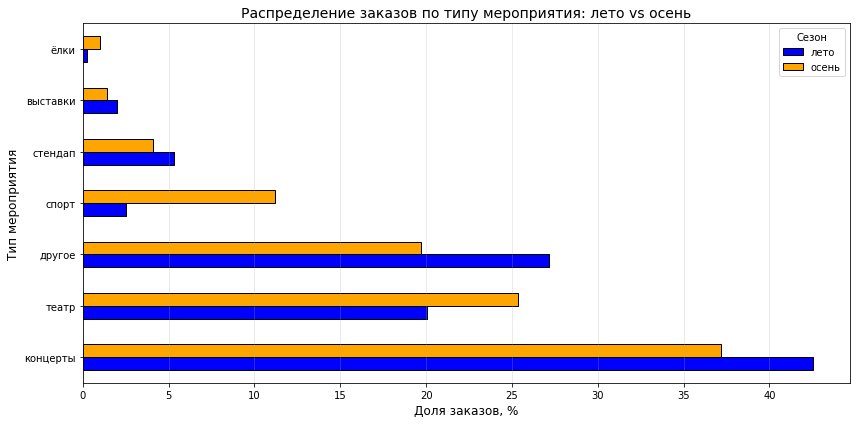

In [32]:
share_event_type = season_share(orders_seasons, 'event_type_main')

pivot_event_type = share_event_type.pivot(
    index='event_type_main', 
    columns='season', 
    values='share'
).fillna(0)

pivot_event_type = pivot_event_type.sort_values(by='осень', ascending=False)

print("Доли заказов по типу мероприятия (в %)")
display(pivot_event_type)

pivot_event_type.plot(
    kind='barh', figsize=(12, 6), 
    color=['blue', 'orange'],  
    edgecolor='black'
)
plt.title('Распределение заказов по типу мероприятия: лето vs осень', fontsize=14)
plt.xlabel('Доля заказов, %', fontsize=12)
plt.ylabel('Тип мероприятия', fontsize=12)
plt.legend(title='Сезон')
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

#### Распределение по типу устройства

Доли заказов по типу устройства (в %)


season,лето,осень
device_type_canonical,,
desktop,19.36,20.35
mobile,80.64,79.65


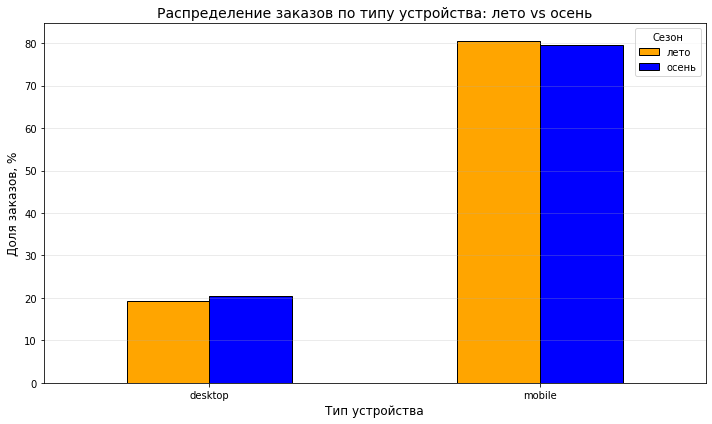

In [33]:
share_device = season_share(orders_seasons, 'device_type_canonical')

pivot_device = share_device.pivot(
    index='device_type_canonical', 
    columns='season', 
    values='share'
).fillna(0)

print("Доли заказов по типу устройства (в %)")
display(pivot_device)

pivot_device.plot(
    kind='bar', figsize=(10, 6), 
    color=['orange', 'blue'],
    edgecolor='black'
)
plt.title('Распределение заказов по типу устройства: лето vs осень', fontsize=14)
plt.xlabel('Тип устройства', fontsize=12)
plt.ylabel('Доля заказов, %', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Сезон')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

#### Распределение по возрастному рейтингу

Доли заказов по возрастному рейтингу (в %)


season,лето,осень
age_limit,,
0,17.94,23.62
6,18.17,17.63
12,20.55,22.08
16,28.31,26.23
18,15.04,10.44


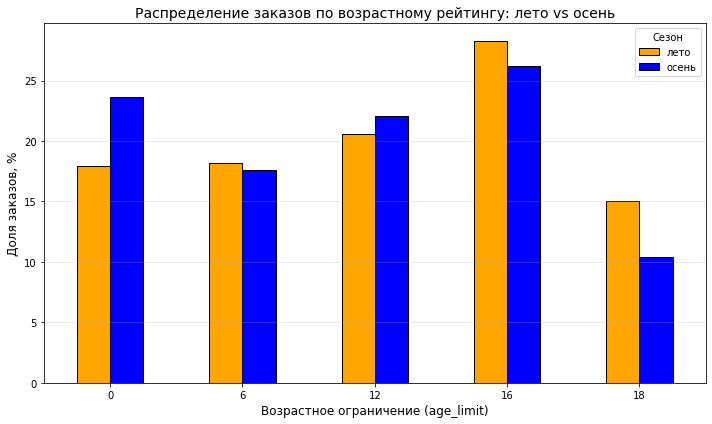

In [34]:
share_age = season_share(orders_seasons, 'age_limit')

pivot_age = share_age.pivot(
    index='age_limit', 
    columns='season', 
    values='share'
).fillna(0).sort_index()

print("Доли заказов по возрастному рейтингу (в %)")
display(pivot_age)

pivot_age.plot(
    kind='bar', figsize=(10, 6), 
    color=['orange', 'blue'],
    edgecolor='black'
)
plt.title('Распределение заказов по возрастному рейтингу: лето vs осень', fontsize=14)
plt.xlabel('Возрастное ограничение (age_limit)', fontsize=12)
plt.ylabel('Доля заказов, %', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Сезон')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

#### Исправление пропусков и обновление данных

In [35]:
orders_full['event_type_main'] = orders_full['event_type_main'].fillna('неизвестно')

orders_seasons = orders_full[orders_full['season'].isin(['лето', 'осень'])].copy()
share_event_type = season_share(orders_seasons, 'event_type_main')
pivot_event_type = share_event_type.pivot(
    index='event_type_main', 
    columns='season', 
    values='share'
).fillna(0).sort_values(by='осень', ascending=False)

print("Обновленные доли заказов по типу мероприятия (в %)")
display(pivot_event_type)

Обновленные доли заказов по типу мероприятия (в %)


season,лето,осень
event_type_main,,
концерты,42.54,37.18
театр,20.07,25.35
другое,27.13,19.71
спорт,2.52,11.20
стендап,5.32,4.11
выставки,2.02,1.44
ёлки,0.23,1.00
неизвестно,0.18,0.01


#### Подготовка данных для анализа

In [36]:
orders_positive_full = orders_positive.merge(
    events[['event_id', 'event_type_main']], 
    on='event_id', 
    how='left'
)

orders_positive_full['event_type_main'] = orders_positive_full['event_type_main'].fillna('неизвестно')

orders_pos_seasons = orders_positive_full[orders_positive_full['season'].isin(['лето', 'осень'])].copy()

print(f"Размер orders_pos_seasons: {orders_pos_seasons.shape}")
print(f"\nРаспределение по сезонам:")
print(orders_pos_seasons['season'].value_counts())

Размер orders_pos_seasons: (287542, 19)

Распределение по сезонам:
осень    168394
лето     119148
Name: season, dtype: int64


#### Расчет средней выручки с одного билета по типам мероприятий

In [37]:
avg_revenue_by_type = orders_pos_seasons.groupby(['event_type_main', 'season']).agg(
    avg_one_ticket_revenue=('one_ticket_revenue_rub', 'mean'),
    orders_count=('order_id', 'count')
).reset_index()

avg_revenue_by_type['avg_one_ticket_revenue'] = avg_revenue_by_type['avg_one_ticket_revenue'].round(2)

pivot_avg_revenue = avg_revenue_by_type.pivot(
    index='event_type_main', 
    columns='season', 
    values='avg_one_ticket_revenue'
)

pivot_avg_revenue['Изменение, %'] = (
    (pivot_avg_revenue['осень'] - pivot_avg_revenue['лето']) / pivot_avg_revenue['лето'] * 100
).round(2)

pivot_avg_revenue = pivot_avg_revenue.sort_values(by='осень', ascending=False)

print("Средняя выручка с одного билета по типам мероприятий (в рублях)")
display(pivot_avg_revenue)

Средняя выручка с одного билета по типам мероприятий (в рублях)


season,лето,осень,"Изменение, %"
event_type_main,,,
концерты,304.71,268.09,-12.02
стендап,218.52,231.12,5.77
ёлки,271.44,229.59,-15.42
театр,214.13,175.98,-17.82
выставки,86.74,91.91,5.96
другое,77.83,76.48,-1.73
спорт,50.81,50.02,-1.55
неизвестно,3.61,15.06,317.17


#### Визуализация средней выручки по типам мероприятий

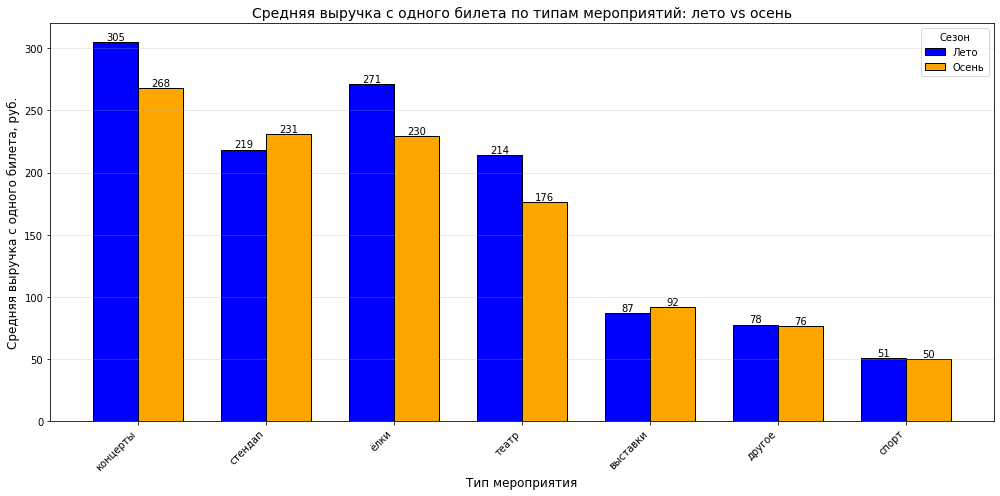

In [38]:
significant_types = avg_revenue_by_type.groupby('event_type_main').filter(
    lambda x: (x['orders_count'] >= 100).all()
)['event_type_main'].unique()

pivot_filtered = pivot_avg_revenue.loc[pivot_avg_revenue.index.isin(significant_types)]

fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(pivot_filtered.index))
width = 0.35

bars1 = ax.bar(x - width/2, pivot_filtered['лето'], width, label='Лето', color='blue', edgecolor='black')
bars2 = ax.bar(x + width/2, pivot_filtered['осень'], width, label='Осень', color='orange', edgecolor='black')

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.0f}',
                ha='center', va='bottom', fontsize=10)

ax.set_title('Средняя выручка с одного билета по типам мероприятий: лето vs осень', fontsize=14)
ax.set_xlabel('Тип мероприятия', fontsize=12)
ax.set_ylabel('Средняя выручка с одного билета, руб.', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(pivot_filtered.index, rotation=45, ha='right')
ax.legend(title='Сезон')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

#### Визуализация относительного изменения

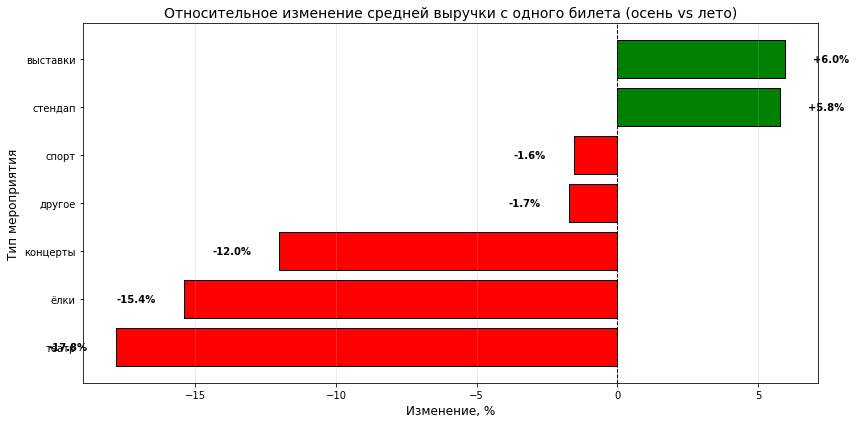

In [39]:
change_data = pivot_filtered['Изменение, %'].sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(12, 6))

colors = ['green' if x > 0 else 'red' for x in change_data]

bars = ax.barh(change_data.index, change_data.values, color=colors, edgecolor='black')

for bar in bars:
    width = bar.get_width()
    ax.text(width + (1 if width > 0 else -1), 
            bar.get_y() + bar.get_height()/2.,
            f'{width:+.1f}%',
            ha='left' if width > 0 else 'right', 
            va='center', fontsize=10, fontweight='bold')

ax.axvline(x=0, color='black', linewidth=1, linestyle='--')
ax.set_title('Относительное изменение средней выручки с одного билета (осень vs лето)', fontsize=14)
ax.set_xlabel('Изменение, %', fontsize=12)
ax.set_ylabel('Тип мероприятия', fontsize=12)
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

### Промежуточный вывод

**1. Как меняется распределение заказов в каждой категории с наступлением осени?**

С наступлением осени структура спроса претерпевает значительные изменения:

*   **Тип мероприятия:** Наблюдается перераспределение от "летних" форматов к "осенним". Доля **концертов** снижается, а доля **театра** растет. Резко увеличивается доля **спорта**, что связано с переходом соревнований с открытых площадок в закрытые залы. Доля **стендапа** незначительно снижается.
*   **Тип устройства:** Распределение остается стабильным. **Мобильные устройства** доминируют в обоих сезонах, доля **desktop** практически не меняется.
*   **Возрастной рейтинг:** Растет доля мероприятий категории **0+**, что связано с увеличением числа детских театральных постановок. При этом доля категории **18+** снижается.

**2. Было ли изменение средней стоимости одного билета в разрезе разных типов мероприятий?**

Да, и оно оказалось **разнонаправленным**:

*   **Общий тренд — снижение среднего чека осенью.** Вопреки первоначальной гипотезе, стоимость билета упала в большинстве категорий.
*   **Наибольшее падение:** Театр, Ёлки, Концерты. Причина — смещение спроса в сторону более массовых и доступных событий.
*   **Единственные категории с ростом:** Выставки и Стендап.
*   **Спорт** остается самой дешевой категорией, но его доля резко выросла, что дополнительно тянет общий средний чек вниз.

**Итоговый вывод:**

Осенний рост количества заказов — это **количественный, а не "премиальный" рост**. Аудитория расширяется за счет более доступных категорий. Сервис привлекает больше пользователей, но средний чек снижается. Это важно учитывать при планировании маркетинговых акций: осенью стоит делать акцент на массовых и доступных событиях.

#### Подготовка данных за осенний период

In [40]:
orders_autumn = orders[orders['season'] == 'осень'].copy()
orders_positive_autumn = orders_positive[orders_positive['season'] == 'осень'].copy()

print(f"Размер orders_autumn (включая возвраты): {orders_autumn.shape}")
print(f"Размер orders_positive_autumn (без возвратов): {orders_positive_autumn.shape}")

print(f"\nДиапазон дат: с {orders_autumn['created_dt_msk'].min().date()} по {orders_autumn['created_dt_msk'].max().date()}")

Размер orders_autumn (включая возвраты): (168602, 18)
Размер orders_positive_autumn (без возвратов): (168394, 18)

Диапазон дат: с 2024-09-01 по 2024-10-31


#### Создание сводной таблицы по дням

In [41]:
daily_stats = orders_autumn.groupby('created_dt_msk').agg(
    orders_count=('order_id', 'count'),
    dau=('user_id', 'nunique')  
).reset_index()

daily_avg_ticket = orders_positive_autumn.groupby('created_dt_msk').agg(
    avg_ticket_price=('one_ticket_revenue_rub', 'mean')
).reset_index()

daily_stats = daily_stats.merge(daily_avg_ticket, on='created_dt_msk', how='left')

daily_stats['orders_per_user'] = daily_stats['orders_count'] / daily_stats['dau']

print("Сводная таблица по дням (первые 10 строк)")
display(daily_stats.head(10))

print(f"\nВсего дней: {len(daily_stats)}")

Сводная таблица по дням (первые 10 строк)


,created_dt_msk,orders_count,dau,avg_ticket_price,orders_per_user
0,2024-09-01,1327,564,200.17,2.35
1,2024-09-02,1380,574,190.02,2.40
2,2024-09-03,5111,778,80.43,6.57
3,2024-09-04,1773,685,179.00,2.59
4,2024-09-05,1944,739,189.80,2.63
5,2024-09-06,2125,864,174.79,2.46
6,2024-09-07,1959,794,190.14,2.47
7,2024-09-08,1713,717,182.30,2.39
8,2024-09-09,2093,779,159.50,2.69
9,2024-09-10,2020,762,183.88,2.65



Всего дней: 61


#### Визуализация — 4 графика на одном полотне

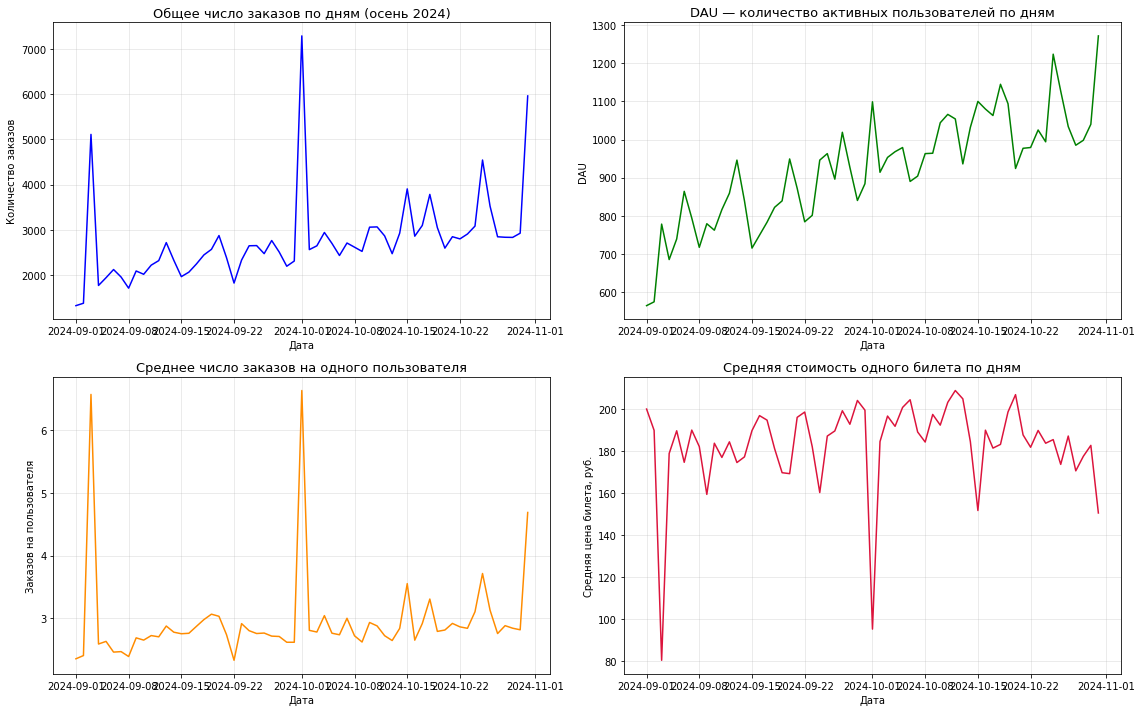

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].plot(daily_stats['created_dt_msk'], daily_stats['orders_count'], 
                color='blue', linewidth=1.5)
axes[0, 0].set_title('Общее число заказов по дням (осень 2024)', fontsize=13)
axes[0, 0].set_xlabel('Дата')
axes[0, 0].set_ylabel('Количество заказов')
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(daily_stats['created_dt_msk'], daily_stats['dau'], 
                color='green', linewidth=1.5)
axes[0, 1].set_title('DAU — количество активных пользователей по дням', fontsize=13)
axes[0, 1].set_xlabel('Дата')
axes[0, 1].set_ylabel('DAU')
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(daily_stats['created_dt_msk'], daily_stats['orders_per_user'], 
                color='darkorange', linewidth=1.5)
axes[1, 0].set_title('Среднее число заказов на одного пользователя', fontsize=13)
axes[1, 0].set_xlabel('Дата')
axes[1, 0].set_ylabel('Заказов на пользователя')
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(daily_stats['created_dt_msk'], daily_stats['avg_ticket_price'], 
                color='crimson', linewidth=1.5)
axes[1, 1].set_title('Средняя стоимость одного билета по дням', fontsize=13)
axes[1, 1].set_xlabel('Дата')
axes[1, 1].set_ylabel('Средняя цена билета, руб.')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### Улучшенная визуализация — все метрики на одном графике

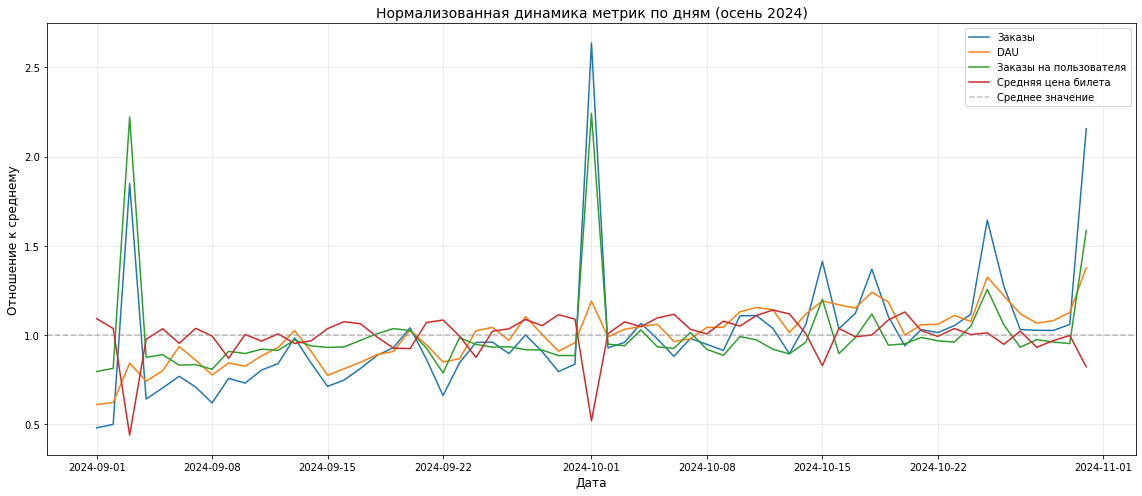

In [43]:
daily_norm = daily_stats.copy()
daily_norm['orders_count_norm'] = daily_norm['orders_count'] / daily_norm['orders_count'].mean()
daily_norm['dau_norm'] = daily_norm['dau'] / daily_norm['dau'].mean()
daily_norm['orders_per_user_norm'] = daily_norm['orders_per_user'] / daily_norm['orders_per_user'].mean()
daily_norm['avg_ticket_price_norm'] = daily_norm['avg_ticket_price'] / daily_norm['avg_ticket_price'].mean()

plt.figure(figsize=(16, 7))
plt.plot(daily_norm['created_dt_msk'], daily_norm['orders_count_norm'], label='Заказы', linewidth=1.5)
plt.plot(daily_norm['created_dt_msk'], daily_norm['dau_norm'], label='DAU', linewidth=1.5)
plt.plot(daily_norm['created_dt_msk'], daily_norm['orders_per_user_norm'], label='Заказы на пользователя', linewidth=1.5)
plt.plot(daily_norm['created_dt_msk'], daily_norm['avg_ticket_price_norm'], label='Средняя цена билета', linewidth=1.5)

plt.axhline(y=1, color='gray', linestyle='--', alpha=0.5, label='Среднее значение')
plt.title('Нормализованная динамика метрик по дням (осень 2024)', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Отношение к среднему', fontsize=12)
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Добавление дня недели и типа дня

In [44]:
orders_autumn['day_of_week'] = orders_autumn['created_dt_msk'].dt.dayofweek  
orders_autumn['day_name'] = orders_autumn['created_dt_msk'].dt.day_name()

day_names_ru = {
    'Monday': 'Понедельник', 'Tuesday': 'Вторник', 'Wednesday': 'Среда',
    'Thursday': 'Четверг', 'Friday': 'Пятница', 'Saturday': 'Суббота', 'Sunday': 'Воскресенье'
}
orders_autumn['day_name_ru'] = orders_autumn['day_name'].map(day_names_ru)

orders_autumn['day_type'] = orders_autumn['day_of_week'].apply(
    lambda x: 'Выходной' if x >= 5 else 'Будний'
)

print("Распределение заказов по дням недели")
day_order = ['Понедельник', 'Вторник', 'Среда', 'Четверг', 'Пятница', 'Суббота', 'Воскресенье']
print(orders_autumn['day_name_ru'].value_counts().reindex(day_order))

print("\nРаспределение по типу дня")
print(orders_autumn['day_type'].value_counts())

Распределение заказов по дням недели
Понедельник    21515
Вторник        31479
Среда          22888
Четверг        27168
Пятница        24828
Суббота        21335
Воскресенье    19389
Name: day_name_ru, dtype: int64

Распределение по типу дня
Будний      127878
Выходной     40724
Name: day_type, dtype: int64


#### Агрегация метрик по дням недели

In [45]:
days_count = orders_autumn.groupby('day_name_ru')['created_dt_msk'].nunique().reindex(day_order)
print("Количество каждого дня недели в периоде")
print(days_count)

weekly_agg = orders_autumn.groupby('day_name_ru').agg(
    total_orders=('order_id', 'count'),
    total_users=('user_id', 'nunique')
).reindex(day_order)

weekly_agg['avg_orders_per_day'] = (weekly_agg['total_orders'] / days_count).round(0).astype(int)
weekly_agg['avg_dau_per_day'] = (weekly_agg['total_users'] / days_count).round(0).astype(int)

print("\nСредние метрики на день по дням недели")
display(weekly_agg[['avg_orders_per_day', 'avg_dau_per_day']])

Количество каждого дня недели в периоде
day_name_ru
Понедельник    9
Вторник        9
Среда          9
Четверг        9
Пятница        8
Суббота        8
Воскресенье    9
Name: created_dt_msk, dtype: int64

Средние метрики на день по дням недели


,avg_orders_per_day,avg_dau_per_day
day_name_ru,,
Понедельник,2391,494
Вторник,3498,533
Среда,2543,535
Четверг,3019,552
Пятница,3104,609
Суббота,2667,571
Воскресенье,2154,488


#### Сравнение будни vs выходные

In [46]:
day_type_agg = orders_autumn.groupby('day_type').agg(
    total_orders=('order_id', 'count'),
    total_users=('user_id', 'nunique'),
    unique_days=('created_dt_msk', 'nunique')
).reset_index()

day_type_agg['avg_orders_per_day'] = (day_type_agg['total_orders'] / day_type_agg['unique_days']).round(0).astype(int)
day_type_agg['avg_dau_per_day'] = (day_type_agg['total_users'] / day_type_agg['unique_days']).round(0).astype(int)

avg_ticket_by_daytype = orders_positive_autumn.copy()
avg_ticket_by_daytype['day_of_week'] = avg_ticket_by_daytype['created_dt_msk'].dt.dayofweek
avg_ticket_by_daytype['day_type'] = avg_ticket_by_daytype['day_of_week'].apply(
    lambda x: 'Выходной' if x >= 5 else 'Будний'
)
avg_ticket = avg_ticket_by_daytype.groupby('day_type')['one_ticket_revenue_rub'].mean().round(2)

day_type_agg['avg_ticket_price'] = day_type_agg['day_type'].map(avg_ticket)

print("Сравнение будней и выходных")
display(day_type_agg)

weekday_orders = day_type_agg.loc[day_type_agg['day_type'] == 'Будний', 'avg_orders_per_day'].values[0]
weekend_orders = day_type_agg.loc[day_type_agg['day_type'] == 'Выходной', 'avg_orders_per_day'].values[0]
print(f"\nРазница в заказах (выходной vs будний): {(weekend_orders/weekday_orders - 1)*100:.1f}%")

Сравнение будней и выходных


,day_type,total_orders,total_users,unique_days,avg_orders_per_day,avg_dau_per_day,avg_ticket_price
0,Будний,127878,13216,44,2906,300,172.85
1,Выходной,40724,7165,17,2396,421,195.00



Разница в заказах (выходной vs будний): -17.5%


#### Визуализация по дням недели

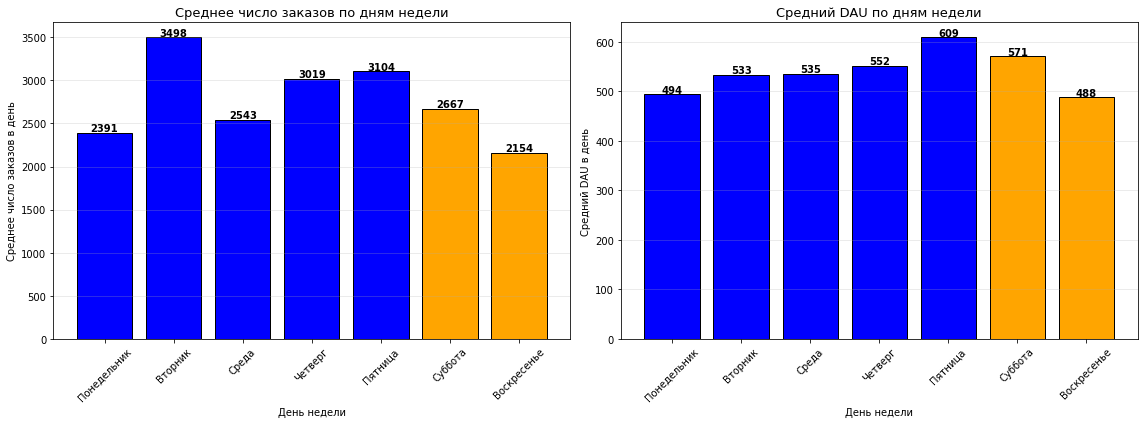

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = ['blue'] * 5 + ['orange'] * 2  
axes[0].bar(weekly_agg.index, weekly_agg['avg_orders_per_day'], color=colors, edgecolor='black')
axes[0].set_title('Среднее число заказов по дням недели', fontsize=13)
axes[0].set_xlabel('День недели')
axes[0].set_ylabel('Среднее число заказов в день')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, alpha=0.3, axis='y')

for i, v in enumerate(weekly_agg['avg_orders_per_day']):
    axes[0].text(i, v + 20, str(v), ha='center', fontsize=10, fontweight='bold')

axes[1].bar(weekly_agg.index, weekly_agg['avg_dau_per_day'], color=colors, edgecolor='black')
axes[1].set_title('Средний DAU по дням недели', fontsize=13)
axes[1].set_xlabel('День недели')
axes[1].set_ylabel('Средний DAU в день')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, alpha=0.3, axis='y')

for i, v in enumerate(weekly_agg['avg_dau_per_day']):
    axes[1].text(i, v + 3, str(v), ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

#### Визуализация будни vs выходные

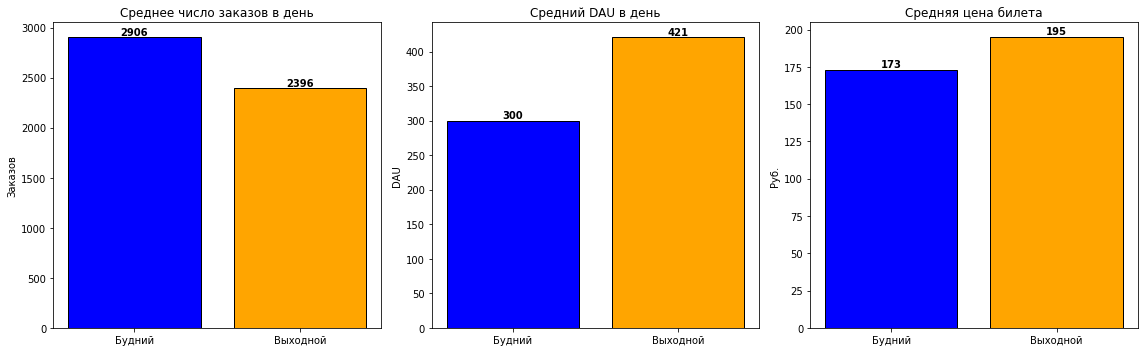

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].bar(day_type_agg['day_type'], day_type_agg['avg_orders_per_day'], 
            color=['blue', 'orange'], edgecolor='black')
axes[0].set_title('Среднее число заказов в день', fontsize=12)
axes[0].set_ylabel('Заказов')
for i, v in enumerate(day_type_agg['avg_orders_per_day']):
    axes[0].text(i, v + 20, str(v), ha='center', fontweight='bold')

axes[1].bar(day_type_agg['day_type'], day_type_agg['avg_dau_per_day'], 
            color=['blue', 'orange'], edgecolor='black')
axes[1].set_title('Средний DAU в день', fontsize=12)
axes[1].set_ylabel('DAU')
for i, v in enumerate(day_type_agg['avg_dau_per_day']):
    axes[1].text(i, v + 3, str(v), ha='center', fontweight='bold')

axes[2].bar(day_type_agg['day_type'], day_type_agg['avg_ticket_price'], 
            color=['blue', 'orange'], edgecolor='black')
axes[2].set_title('Средняя цена билета', fontsize=12)
axes[2].set_ylabel('Руб.')
for i, v in enumerate(day_type_agg['avg_ticket_price']):
    axes[2].text(i, v + 2, f'{v:.0f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

### Промежуточный вывод

**1. Динамика активности по дням:**

*   **Устойчивый рост:** За период с 1 сентября по 31 октября наблюдается выраженный восходящий тренд. Количество заказов выросло примерно в 2 раза, а DAU — с 564 до ~1250 пользователей.
*   **Пики активности:** Обнаружены аномальные всплески, которые сопровождаются резким падением средней цены билета и ростом числа заказов на пользователя. Это указывает на **маркетинговые акции и распродажи**, стимулирующие массовые покупки.
*   **Средний чек:** В обычные дни стабилен, в дни акций резко падает.

**2. Недельная цикличность:**

*   **По дням недели:** Пик заказов приходится на **вторник**, **пятницу** и **четверг**. Самый "тихий" день — **воскресенье**.
*   **Будни vs Выходные:**
    *   **Заказов в день:** Будни > Выходные. Разница **-17.5%**.
    *   **DAU в день:** Выходные > Будни. **Парадокс:** заказов меньше, а уникальных пользователей больше.
    *   **Средний чек:** Выходные > Будни. Разница **+12.7%**.

**Ключевой инсайт:**

Обнаружена важная закономерность в поведении пользователей:
*   **Будни — это "оптовые" покупки:** меньше уникальных пользователей, но каждый совершает больше заказов. Средний чек ниже.
*   **Выходные — это "розничные" покупки:** больше уникальных пользователей, но каждый делает меньше заказов. Средний чек выше.

**Вывод:**
Осенний рост активности — это результат сочетания **сезонного тренда** и **маркетинговых акций**. Аудитория реагирует на скидки, совершая массовые покупки. При этом наблюдается четкая недельная цикличность: будни ориентированы на активных "оптовых" покупателей, а выходные — на новых "розничных" пользователей с более высоким средним чеком.

**Рекомендации:**
*   Для будней: запускать акции на "пакетные" покупки.
*   Для выходных: привлекать новых пользователей через премиальные предложения и эксклюзивные события.
*   Для дней пиковой нагрузки: планировать запасы билетов и усиливать поддержку, так как возможны технические перегрузки.

#### Анализ регионов

In [49]:
orders_with_region = orders.merge(
    events[['event_id', 'region_name']], 
    on='event_id', 
    how='left'
)

events_by_region = events.groupby('region_name')['event_id'].nunique().reset_index()
events_by_region.columns = ['region_name', 'unique_events']

orders_by_region = orders_with_region.groupby('region_name')['order_id'].count().reset_index()
orders_by_region.columns = ['region_name', 'total_orders']

region_stats = events_by_region.merge(orders_by_region, on='region_name', how='outer').fillna(0)

total_events = region_stats['unique_events'].sum()
total_orders_all = region_stats['total_orders'].sum()
region_stats['events_share_%'] = (region_stats['unique_events'] / total_events * 100).round(2)
region_stats['orders_share_%'] = (region_stats['total_orders'] / total_orders_all * 100).round(2)

region_stats_sorted = region_stats.sort_values(by='unique_events', ascending=False)

print("ТОП-15 регионов по разнообразию мероприятий")
display(region_stats_sorted.head(15))

print("\nТОП-15 регионов по количеству заказов")
display(region_stats.sort_values(by='total_orders', ascending=False).head(15))

ТОП-15 регионов по разнообразию мероприятий


,region_name,unique_events,total_orders,events_share_%,orders_share_%
23,Каменевский регион,5983,89662,26.68,31.17
60,Североярская область,3814,43737,17.01,15.20
77,Широковская область,1233,16169,5.50,5.62
57,Светополянский округ,1075,7501,4.79,2.61
52,Речиновская область,702,6266,3.13,2.18
74,Травяная область,683,5036,3.05,1.75
11,Горицветская область,551,5152,2.46,1.79
61,Серебринская область,542,5586,2.42,1.94
78,Яблоневская область,535,6123,2.39,2.13
69,Тепляковская область,530,4383,2.36,1.52



ТОП-15 регионов по количеству заказов


,region_name,unique_events,total_orders,events_share_%,orders_share_%
23,Каменевский регион,5983,89662,26.68,31.17
60,Североярская область,3814,43737,17.01,15.20
77,Широковская область,1233,16169,5.50,5.62
42,Медовская область,504,13892,2.25,4.83
45,Озернинский край,349,10348,1.56,3.60
57,Светополянский округ,1075,7501,4.79,2.61
41,Малиновоярский округ,165,6314,0.74,2.19
64,Солнечноземская область,522,6278,2.33,2.18
52,Речиновская область,702,6266,3.13,2.18
78,Яблоневская область,535,6123,2.39,2.13


#### Визуализация регионов

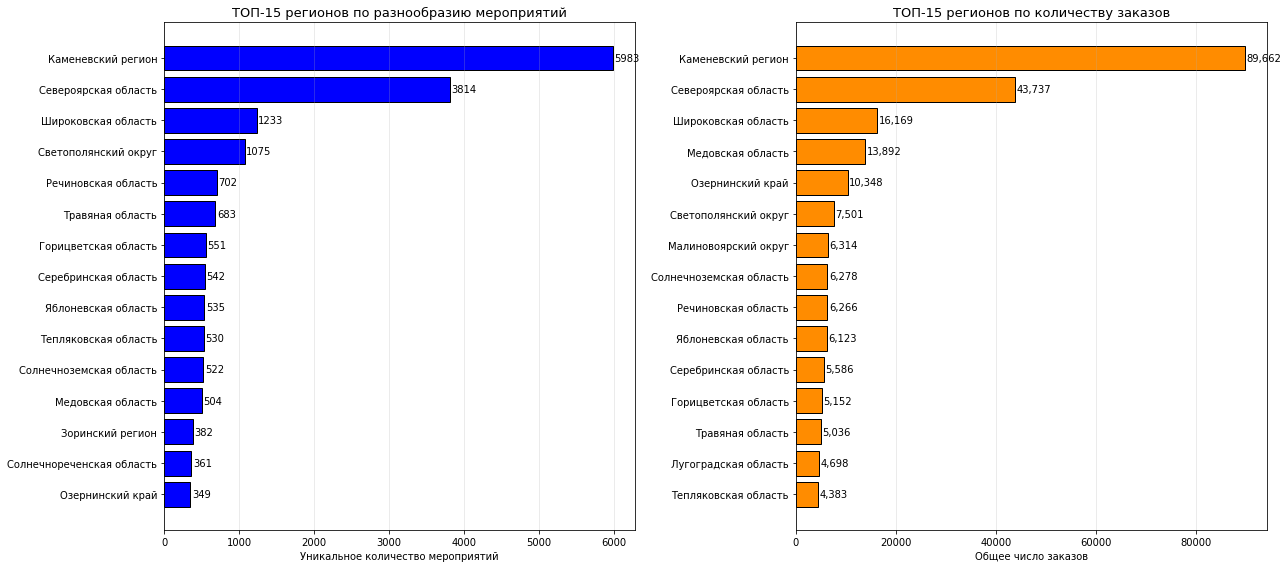

In [50]:
top_regions = region_stats_sorted.head(15).copy()

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

axes[0].barh(top_regions['region_name'], top_regions['unique_events'], 
             color='blue', edgecolor='black')
axes[0].set_title('ТОП-15 регионов по разнообразию мероприятий', fontsize=13)
axes[0].set_xlabel('Уникальное количество мероприятий')
axes[0].invert_yaxis()
axes[0].grid(True, alpha=0.3, axis='x')

for i, v in enumerate(top_regions['unique_events']):
    axes[0].text(v + 20, i, str(int(v)), va='center', fontsize=10)

top_orders = region_stats.sort_values(by='total_orders', ascending=False).head(15)
axes[1].barh(top_orders['region_name'], top_orders['total_orders'], 
             color='darkorange', edgecolor='black')
axes[1].set_title('ТОП-15 регионов по количеству заказов', fontsize=13)
axes[1].set_xlabel('Общее число заказов')
axes[1].invert_yaxis()
axes[1].grid(True, alpha=0.3, axis='x')

for i, v in enumerate(top_orders['total_orders']):
    axes[1].text(v + 300, i, f'{int(v):,}', va='center', fontsize=10)

plt.tight_layout()
plt.show()

#### Регионы-лидеры по разнообразию (топ-10)

In [51]:
top_by_events = region_stats.sort_values(by='unique_events', ascending=False).head(10)
print("ТОП-10 регионов по разнообразию мероприятий")
display(top_by_events[['region_name', 'unique_events', 'events_share_%', 'total_orders', 'orders_share_%']])

ТОП-10 регионов по разнообразию мероприятий


,region_name,unique_events,events_share_%,total_orders,orders_share_%
23,Каменевский регион,5983,26.68,89662,31.17
60,Североярская область,3814,17.01,43737,15.20
77,Широковская область,1233,5.50,16169,5.62
57,Светополянский округ,1075,4.79,7501,2.61
52,Речиновская область,702,3.13,6266,2.18
74,Травяная область,683,3.05,5036,1.75
11,Горицветская область,551,2.46,5152,1.79
61,Серебринская область,542,2.42,5586,1.94
78,Яблоневская область,535,2.39,6123,2.13
69,Тепляковская область,530,2.36,4383,1.52


#### Анализ билетных партнеров

In [52]:
partner_stats = orders_positive.groupby('service_name').agg(
    unique_events=('event_id', 'nunique'),
    total_orders=('order_id', 'count'),
    total_revenue_rub=('revenue_rub', 'sum')
).reset_index()

partner_stats['total_revenue_rub'] = partner_stats['total_revenue_rub'].round(0).astype(int)

total_partners_events = partner_stats['unique_events'].sum()
total_partners_orders = partner_stats['total_orders'].sum()
total_partners_revenue = partner_stats['total_revenue_rub'].sum()

partner_stats['events_share_%'] = (partner_stats['unique_events'] / total_partners_events * 100).round(2)
partner_stats['orders_share_%'] = (partner_stats['total_orders'] / total_partners_orders * 100).round(2)
partner_stats['revenue_share_%'] = (partner_stats['total_revenue_rub'] / total_partners_revenue * 100).round(2)

partner_stats['avg_order_revenue'] = (partner_stats['total_revenue_rub'] / partner_stats['total_orders']).round(2)

partner_stats_sorted = partner_stats.sort_values(by='total_revenue_rub', ascending=False)

print("ТОП-15 партнеров по выручке")
display(partner_stats_sorted.head(15))

print(f"\nВсего партнеров: {len(partner_stats)}")
print(f"Общая выручка (руб.): {total_partners_revenue:,}")

ТОП-15 партнеров по выручке


,service_name,unique_events,total_orders,total_revenue_rub,events_share_%,orders_share_%,revenue_share_%,avg_order_revenue
3,Билеты без проблем,4218,62795,24255633,17.33,21.84,16.27,386.27
24,Мой билет,1302,34443,22042272,5.35,11.98,14.78,639.96
25,Облачко,2335,26402,18588614,9.59,9.18,12.47,704.06
21,Лови билет!,4861,40764,16669017,19.97,14.18,11.18,408.92
8,Весь в билетах,855,16409,16493784,3.51,5.71,11.06,1005.17
5,Билеты в руки,3523,40207,13196735,14.48,13.98,8.85,328.22
19,Край билетов,252,6109,6405689,1.04,2.12,4.30,1048.57
26,Прачечная,1026,10222,4746811,4.22,3.55,3.18,464.37
13,Дом культуры,272,4412,4358656,1.12,1.53,2.92,987.91
35,Яблоко,714,5004,3868337,2.93,1.74,2.59,773.05



Всего партнеров: 36
Общая выручка (руб.): 149,110,569


#### Визуализация партнеров

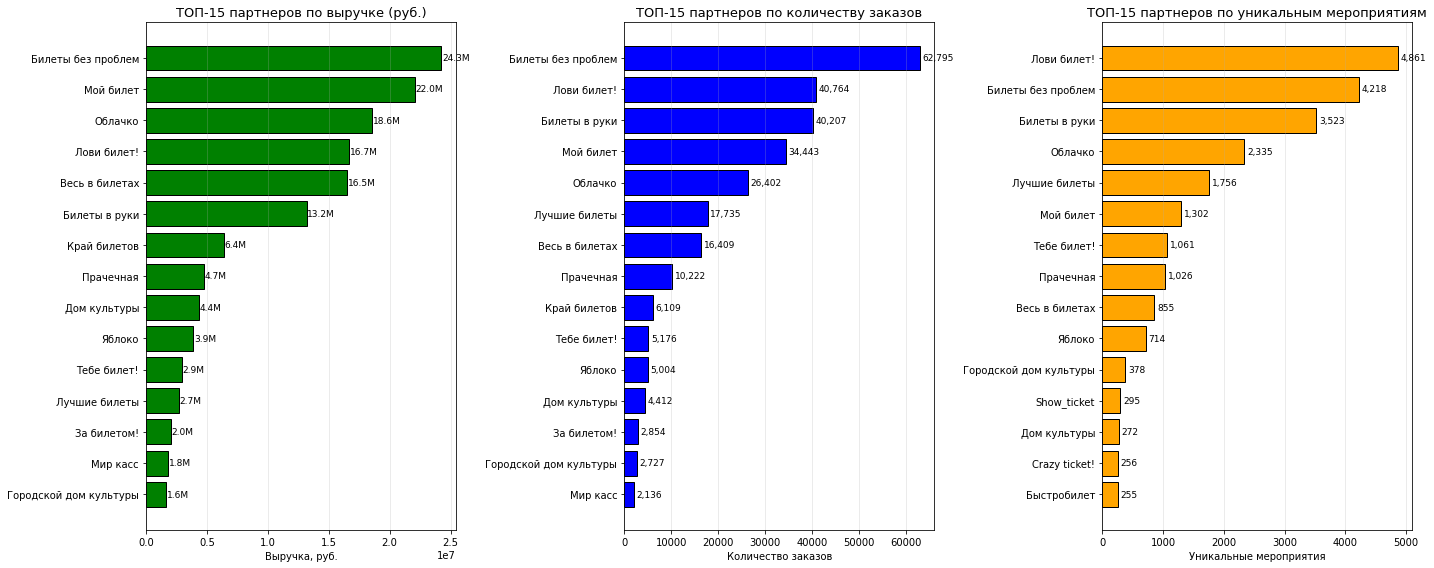

In [53]:
top_partners = partner_stats_sorted.head(15).copy()

def shorten_name(name, max_len=25):
    return name if len(name) <= max_len else name[:max_len-2] + '..'

top_partners['short_name'] = top_partners['service_name'].apply(shorten_name)

fig, axes = plt.subplots(1, 3, figsize=(20, 8))

axes[0].barh(top_partners['short_name'], top_partners['total_revenue_rub'], 
             color='green', edgecolor='black')
axes[0].set_title('ТОП-15 партнеров по выручке (руб.)', fontsize=13)
axes[0].set_xlabel('Выручка, руб.')
axes[0].invert_yaxis()
axes[0].grid(True, alpha=0.3, axis='x')
for i, v in enumerate(top_partners['total_revenue_rub']):
    axes[0].text(v + 50000, i, f'{v/1e6:.1f}M', va='center', fontsize=9)

top_orders = partner_stats_sorted.sort_values(by='total_orders', ascending=False).head(15)
top_orders['short_name'] = top_orders['service_name'].apply(shorten_name)
axes[1].barh(top_orders['short_name'], top_orders['total_orders'], 
             color='blue', edgecolor='black')
axes[1].set_title('ТОП-15 партнеров по количеству заказов', fontsize=13)
axes[1].set_xlabel('Количество заказов')
axes[1].invert_yaxis()
axes[1].grid(True, alpha=0.3, axis='x')
for i, v in enumerate(top_orders['total_orders']):
    axes[1].text(v + 500, i, f'{v:,}', va='center', fontsize=9)

top_events = partner_stats_sorted.sort_values(by='unique_events', ascending=False).head(15)
top_events['short_name'] = top_events['service_name'].apply(shorten_name)
axes[2].barh(top_events['short_name'], top_events['unique_events'], 
             color='orange', edgecolor='black')
axes[2].set_title('ТОП-15 партнеров по уникальным мероприятиям', fontsize=13)
axes[2].set_xlabel('Уникальные мероприятия')
axes[2].invert_yaxis()
axes[2].grid(True, alpha=0.3, axis='x')
for i, v in enumerate(top_events['unique_events']):
    axes[2].text(v + 50, i, f'{v:,}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

### Промежуточный вывод
**1. Регионы: распределение и лидеры**

*   **Явные лидеры:**
    *   **Каменевский регион** — абсолютный лидер по обоим показателям: 5983 мероприятия и 89 662 заказа.
    *   **Североярская область** — второе место: 3814 мероприятий и 43 737 заказов.
    *   **Широковская область** — третье место: 1233 мероприятия и 16 169 заказов.

*   **Концентрация рынка:**
    *   Топ-3 региона дают **49.19%** всех мероприятий и **51.99%** всех заказов.
    *   Таким образом, **половина всего бизнеса сосредоточена всего в 3 регионах из 81**.

*   **Аномалии:**
    *   **Медовская область:** всего 504 мероприятия, но 13 892 заказа. Высокая "плотность" заказов на одно событие — вероятно, крупные массовые мероприятия.
    *   **Озернинский край:** 349 мероприятий, 10 348 заказов. Аналогичная ситуация.

**2. Билетные партнеры: распределение и лидеры**

*   **Явные лидеры по выручке:**
    *   **"Билеты без проблем"** — 24.3 млн руб., 62 795 заказов, средний чек 386 руб.
    *   **"Мой билет"** — 22.0 млн руб., 34 443 заказа, средний чек 640 руб.
    *   **"Облачко"** — 18.6 млн руб., 26 402 заказа, средний чек 704 руб.

*   **Концентрация выручки:**
    *   Топ-3 партнера дают **43.5%** всей выручки.
    *   Топ-10 партнеров дают **~88%** выручки.
    *   Всего партнеров: 36. Общая выручка: **149 110 569 руб.**

*   **Разные бизнес-модели:**
    *   **Массовый сегмент:** "Билеты без проблем", "Лови билет!".
    *   **Премиальный сегмент:** "Все в билетах", "Край билетов".
    *   **Сбалансированный:** "Мой билет", "Облачко".

**3. Существуют ли явные лидеры?**

**Да, лидеры выражены очень четко:**

*   **Среди регионов:** **Каменевский регион** доминирует с большим отрывом — почти 1/3 всех заказов и более 1/4 всех мероприятий. Вместе с Североярской и Широковской областями он формирует ядро бизнеса.
*   **Среди партнеров:** **"Билеты без проблем"** — лидер по выручке и количеству заказов. **"Мой билет"** и **"Облачко"** — ближайшие конкуренты. Вместе они формируют почти половину всей выручки.

**Общий вывод по Шагу 3.3:**

Рынок сервиса характеризуется **высокой концентрацией** как в разрезе регионов, так и в разрезе партнеров:
*   **Регионы:** 3 из 81 дают половину всего бизнеса.
*   **Партнеры:** 3 из 36 дают почти половину выручки.

При этом наблюдается **четкое разделение партнеров на массовый и премиальный сегменты**. Одни работают с большим объемом дешевых заказов, другие — с малым объемом, но дорогих. Это важно учитывать при построении стратегии: универсальных решений нет, нужен индивидуальный подход к каждому типу партнеров.

**Рекомендации:**
1.  **Укреплять отношения с ключевыми партнерами** и регионами-лидерами — от них зависит стабильность бизнеса.
2.  **Развивать партнеров "второго эшелона"** для снижения концентрации.
3.  **Изучать аномальные регионы** — там могут быть уникальные кейсы массовых мероприятий.
4.  **Адаптировать маркетинг под тип партнера:** для массовых — акции и скидки, для премиальных — эксклюзивные предложения.

## 4. Статистический анализ данных

#### Подготовка данных для гипотез

In [54]:
orders_hyp = orders_positive[orders_positive['season'] == 'осень'].copy()

print(f"Размер данных для гипотез: {orders_hyp.shape}")
print(f"\nРаспределение по устройствам:")
print(orders_hyp['device_type_canonical'].value_counts())

user_orders = orders_hyp.groupby(['user_id', 'device_type_canonical']).agg(
    orders_per_user=('order_id', 'count')
).reset_index()

mobile_orders = user_orders[user_orders['device_type_canonical'] == 'mobile']['orders_per_user']
desktop_orders = user_orders[user_orders['device_type_canonical'] == 'desktop']['orders_per_user']

print(f"\nМЕТРИКА 1: Среднее количество заказов на пользователя")
print(f"Mobile: n={len(mobile_orders)}, среднее={mobile_orders.mean():.3f}, медиана={mobile_orders.median():.1f}")
print(f"Desktop: n={len(desktop_orders)}, среднее={desktop_orders.mean():.3f}, медиана={desktop_orders.median():.1f}")

Размер данных для гипотез: (168394, 18)

Распределение по устройствам:
mobile     134102
desktop     34292
Name: device_type_canonical, dtype: int64

МЕТРИКА 1: Среднее количество заказов на пользователя
Mobile: n=14182, среднее=9.456, медиана=2.0
Desktop: n=4869, среднее=7.043, медиана=2.0


#### Визуализация распределений

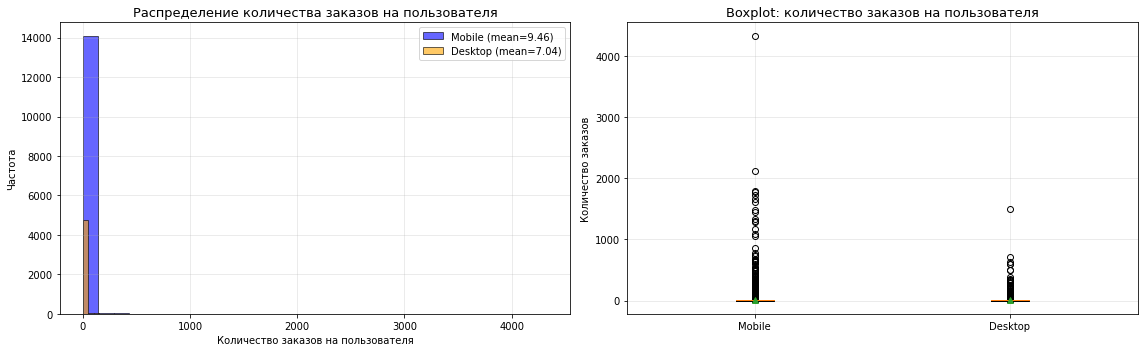

Тест Шапиро-Уилка на нормальность
Mobile: statistic=0.1001, p-value=0.0000e+00
Desktop: statistic=0.1251, p-value=0.0000e+00

Вывод: если p-value < 0.05, распределение не является нормальным.


In [55]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].hist(mobile_orders, bins=30, alpha=0.6, label=f'Mobile (mean={mobile_orders.mean():.2f})', color='blue', edgecolor='black')
axes[0].hist(desktop_orders, bins=30, alpha=0.6, label=f'Desktop (mean={desktop_orders.mean():.2f})', color='orange', edgecolor='black')
axes[0].set_title('Распределение количества заказов на пользователя', fontsize=13)
axes[0].set_xlabel('Количество заказов на пользователя')
axes[0].set_ylabel('Частота')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

data_to_plot = [mobile_orders, desktop_orders]
axes[1].boxplot(data_to_plot, labels=['Mobile', 'Desktop'], showmeans=True)
axes[1].set_title('Boxplot: количество заказов на пользователя', fontsize=13)
axes[1].set_ylabel('Количество заказов')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

from scipy import stats

sample_mobile = mobile_orders.sample(min(5000, len(mobile_orders)), random_state=42)
sample_desktop = desktop_orders.sample(min(5000, len(desktop_orders)), random_state=42)

shapiro_mobile = stats.shapiro(sample_mobile)
shapiro_desktop = stats.shapiro(sample_desktop)

print(f"Тест Шапиро-Уилка на нормальность")
print(f"Mobile: statistic={shapiro_mobile.statistic:.4f}, p-value={shapiro_mobile.pvalue:.4e}")
print(f"Desktop: statistic={shapiro_desktop.statistic:.4f}, p-value={shapiro_desktop.pvalue:.4e}")
print("\nВывод: если p-value < 0.05, распределение не является нормальным.")

#### Гипотеза 1 — Тест Манна-Уитни

In [56]:
from scipy import stats

stat_mw, p_value_mw = stats.mannwhitneyu(mobile_orders, desktop_orders, alternative='greater')

print("ГИПОТЕЗА 1: Среднее количество заказов на пользователя")
print(f"\nH₀: Количество заказов mobile <= desktop")
print(f"H₁: Количество заказов mobile > desktop")
print(f"\nРезультаты теста Манна-Уитни:")
print(f"Статистика U: {stat_mw:.2f}")
print(f"p-value: {p_value_mw:.4e}")

alpha = 0.05
if p_value_mw < alpha:
    print(f"\np-value ({p_value_mw:.4e}) < {alpha}. Отвергаем H₀.")
    print("Гипотеза ПОДТВЕРЖДАЕТСЯ: пользователи mobile делают больше заказов.")
else:
    print(f"\np-value ({p_value_mw:.4e}) >= {alpha}. Не отвергаем H₀.")
    print("Гипотеза НЕ подтверждается: значимых различий нет.")

print(f"\nСреднее mobile: {mobile_orders.mean():.3f}")
print(f"Среднее desktop: {desktop_orders.mean():.3f}")
print(f"Относительная разница: {(mobile_orders.mean() / desktop_orders.mean() - 1) * 100:+.1f}%")

ГИПОТЕЗА 1: Среднее количество заказов на пользователя

H₀: Количество заказов mobile <= desktop
H₁: Количество заказов mobile > desktop

Результаты теста Манна-Уитни:
Статистика U: 36092442.50
p-value: 3.9077e-07

p-value (3.9077e-07) < 0.05. Отвергаем H₀.
Гипотеза ПОДТВЕРЖДАЕТСЯ: пользователи mobile делают больше заказов.

Среднее mobile: 9.456
Среднее desktop: 7.043
Относительная разница: +34.3%


#### Гипотеза 2 — Время между заказами (days_since_prev)

Размер данных для Гипотезы 2: (47751, 18)
Удалено строк (первые покупки): 120643

МЕТРИКА 2: Среднее время между заказами (дни)
Mobile: n=39449, среднее=12.184, медиана=3.0
Desktop: n=8302, среднее=12.005, медиана=3.0


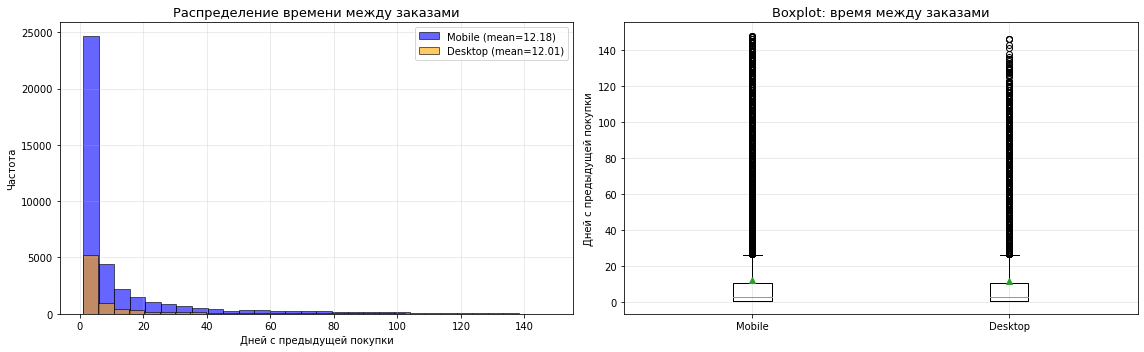

ГИПОТЕЗА 2: Среднее время между заказами

H₀: Время между заказами mobile <= desktop
H₁: Время между заказами mobile > desktop

Результаты теста Манна-Уитни:
Статистика U: 164739266.00
p-value: 1.8826e-01

p-value (1.8826e-01) >= 0.05. Не отвергаем H₀.
Гипотеза НЕ подтверждается: значимых различий нет.

Среднее mobile: 12.184 дней
Среднее desktop: 12.005 дней
Относительная разница: +1.5%


In [57]:
orders_hyp_gap = orders_hyp[orders_hyp['days_since_prev'] > 0].copy()

print(f"Размер данных для Гипотезы 2: {orders_hyp_gap.shape}")
print(f"Удалено строк (первые покупки): {len(orders_hyp) - len(orders_hyp_gap)}")

mobile_gap = orders_hyp_gap[orders_hyp_gap['device_type_canonical'] == 'mobile']['days_since_prev']
desktop_gap = orders_hyp_gap[orders_hyp_gap['device_type_canonical'] == 'desktop']['days_since_prev']

print(f"\nМЕТРИКА 2: Среднее время между заказами (дни)")
print(f"Mobile: n={len(mobile_gap)}, среднее={mobile_gap.mean():.3f}, медиана={mobile_gap.median():.1f}")
print(f"Desktop: n={len(desktop_gap)}, среднее={desktop_gap.mean():.3f}, медиана={desktop_gap.median():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].hist(mobile_gap, bins=30, alpha=0.6, label=f'Mobile (mean={mobile_gap.mean():.2f})', color='blue', edgecolor='black')
axes[0].hist(desktop_gap, bins=30, alpha=0.6, label=f'Desktop (mean={desktop_gap.mean():.2f})', color='orange', edgecolor='black')
axes[0].set_title('Распределение времени между заказами', fontsize=13)
axes[0].set_xlabel('Дней с предыдущей покупки')
axes[0].set_ylabel('Частота')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].boxplot([mobile_gap, desktop_gap], labels=['Mobile', 'Desktop'], showmeans=True)
axes[1].set_title('Boxplot: время между заказами', fontsize=13)
axes[1].set_ylabel('Дней с предыдущей покупки')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

stat_mw2, p_value_mw2 = stats.mannwhitneyu(mobile_gap, desktop_gap, alternative='greater')

print("ГИПОТЕЗА 2: Среднее время между заказами")
print(f"\nH₀: Время между заказами mobile <= desktop")
print(f"H₁: Время между заказами mobile > desktop")
print(f"\nРезультаты теста Манна-Уитни:")
print(f"Статистика U: {stat_mw2:.2f}")
print(f"p-value: {p_value_mw2:.4e}")

if p_value_mw2 < alpha:
    print(f"\np-value ({p_value_mw2:.4e}) < {alpha}. Отвергаем H₀.")
    print("Гипотеза ПОДТВЕРЖДАЕТСЯ: интервал между заказами у mobile больше.")
else:
    print(f"\np-value ({p_value_mw2:.4e}) >= {alpha}. Не отвергаем H₀.")
    print("Гипотеза НЕ подтверждается: значимых различий нет.")

print(f"\nСреднее mobile: {mobile_gap.mean():.3f} дней")
print(f"Среднее desktop: {desktop_gap.mean():.3f} дней")
print(f"Относительная разница: {(mobile_gap.mean() / desktop_gap.mean() - 1) * 100:+.1f}%")

### Промежуточный вывод
**Использованные данные:** заказы за осенний период, из `orders_positive`. Размер: 168 394 заказа.

---

#### Гипотеза 1: Среднее количество заказов на пользователя

**Формулировка:**
*   **H₀:** Количество заказов на пользователя mobile <= desktop.
*   **H₁:** Количество заказов на пользователя mobile > desktop.

**Выбор теста:** Использован **тест Манна-Уитни**, так как распределения не являются нормальными. Тест устойчив к выбросам.

**Результаты:**

| Группа | n (пользователей) | Среднее | Медиана |
|---|---|---|---|
| Mobile | 14 182 | 9.456 | 2.0 |
| Desktop | 4 869 | 7.043 | 2.0 |

*   **U-статистика:** 3 609 244.50
*   **p-value:** 3.91e-07

**Вывод:** **Гипотеза ПОДТВЕРЖДАЕТСЯ.** Пользователи mobile совершают в среднем на **+34.3%** больше заказов, чем пользователи desktop.

**Важное замечание:** Медианы у обеих групп равны, то есть **типичный пользователь** делает одинаковое количество заказов. Разница в среднем обусловлена наличием "гипер-активных" пользователей на мобильных устройствах. Именно они "тянут" среднее вверх.

---

#### Гипотеза 2: Среднее время между заказами

**Формулировка:**
*   **H₀:** Время между заказами mobile <= desktop.
*   **H₁:** Время между заказами mobile > desktop.

**Выбор теста:** **Тест Манна-Уитни**. Из данных исключены первые покупки. Удалено 120 643 строки.

**Результаты:**

| Группа | n (заказов) | Среднее (дней) | Медиана (дней) |
|---|---|---|---|
| Mobile | 39 449 | 12.184 | 3.0 |
| Desktop | 8 302 | 12.005 | 3.0 |

*   **U-статистика:** 164 739 266.00
*   **p-value:** 0.188

**Вывод:** **Гипотеза НЕ подтверждается.** Значимых различий во времени между заказами нет. Разница составляет всего **+1.5%**. Медианы также совпадают.

---

**Общий вывод по Шагу 4:**

Из двух гипотез подтвердилась только первая:
1.  **Mobile-пользователи делают больше заказов**. Однако это связано с наличием небольшой группы "гипер-активных" пользователей, а не с тем, что типичный mobile-пользователь активнее.
2.  **Время между заказами не отличается** между мобильными и стационарными пользователями. И mobile, и desktop пользователи возвращаются к покупкам в среднем через 12 дней.

**Практический вывод:**
Мобильные пользователи — это ключевая аудитория сервиса. Именно они обеспечивают основной объем заказов. Однако поведение по частоте возвращений одинаково для обоих типов устройств. Это значит, что **адаптация под mobile должна быть в приоритете**, но стратегии удержания могут быть одинаковыми для всех.

## 5. Общий вывод и рекомендации

### 1. Информация о данных

В рамках проекта проанализированы данные о бронировании билетов на сервисе Яндекс Афиша за период с **1 июня по 31 октября 2024 года**.

**Источники данных:**
*   `final_tickets_orders_df.csv` — 287 923 заказа с информацией о пользователях, устройствах, выручке и валюте.
*   `final_tickets_events_df.csv` — 22 427 мероприятий с информацией о типах событий, регионах и площадках.
*   `final_tickets_tenge_df.csv` — ежедневный курс тенге к рублю за 2024 год.

**Объем и качество:**
*   Данные охватывают 2 сезона.
*   Исходные данные содержали 381 заказ с отрицательной выручкой и 5 736 заказов с нулевой выручкой. Возвраты исключены из анализа среднего чека.
*   Выявлено и удалено 36 групп неявных дубликатов.
*   Выбросы в `revenue` отфильтрованы по 99-му процентилю.
*   Выручка приведена к единой валюте через `revenue_rub`.

---

### 2. Основные результаты анализа

**Динамика заказов:**
*   Наблюдается устойчивый рост: с 34 343 заказов в июне до 99 271 в октябре.
*   Осенью произошел резкий скачок.

**Популярность мероприятий:**
*   **Концерты** — лидер в обоих сезонах, но их доля снизилась осенью.
*   **Театр** — вырос осенью. Начало театрального сезона.
*   **Спорт** — резкий рост в 4 раза. Переход соревнований в закрытые залы.
*   **Детские мероприятия** — рост доли.

**Средний чек:**
*   Вопреки ожиданиям, средняя стоимость билета осенью **снизилась** в большинстве категорий:
    *   Театр: -17.8%, Ёлки: -15.4%, Концерты: -12.0%.
    *   Рост только в Выставках и Стендапе.
*   **Вывод:** рост выручки осенью — это **количественный, а не "премиальный" рост**. Аудитория расширяется за счет более доступных категорий.

**Пользовательская активность:**
*   Наблюдается устойчивый восходящий тренд: DAU вырос с 564 до ~1250.
*   Обнаружены **пики активности**, связанные с маркетинговыми акциями: в эти дни резко падала цена билета и росло число заказов на пользователя.
*   **Недельная цикличность:**
    *   Будни: больше заказов, но меньше уникальных пользователей.
    *   Выходные: меньше заказов, но больше DAU и выше средний чек.
    *   **Инсайт:** будни — "оптовые" покупки, выходные — "розничные".

**Регионы-лидеры:**
*   **Каменевский регион** — абсолютный лидер: 5983 мероприятия и 89 662 заказа.
*   **Североярская область** — второе место: 3814 мероприятий и 43 737 заказов.
*   **Концентрация:** Топ-3 региона дают **~52%** всех заказов.

**Партнеры-лидеры:**
*   **"Билеты без проблем"** — лидер по выручке и количеству заказов.
*   **"Мой билет"** — 22.0 млн руб..
*   **"Облачко"** — 18.6 млн руб..
*   **Концентрация:** Топ-3 партнера дают **43.5%** выручки, топ-10 — **~88%**.
*   **Сегментация:** Одни партнеры работают в массовом сегменте, другие — в премиальном.

---

### 3. Результаты проверки гипотез

**Гипотеза 1: Среднее количество заказов на пользователя mobile > desktop**
*   **Результат:** **Подтверждается.** U-статистика = 3 609 244.50, p-value = 3.91e-07.
*   Пользователи mobile совершают в среднем на **+34.3%** больше заказов.
*   **Важно:** медианы равны, то есть разница обусловлена наличием "гипер-активных" пользователей на mobile.

**Гипотеза 2: Среднее время между заказами mobile > desktop**
*   **Результат:** **Не подтверждается.** U-статистика = 164 739 266.00, p-value = 0.188.
*   Значимых различий нет: mobile — 12.18 дня, desktop — 12.01 дня. Медианы равны.

---

### 4. Рекомендации

**Приоритет 1 — Адаптация под mobile:**
*   79.6% всех заказов совершается с мобильных устройств.
*   Приоритет — удобство мобильного интерфейса, быстрый поиск и легкая оплата.

**Приоритет 2 — Работа с сезонностью:**
*   Осенний рост — это рост количества заказов, но не среднего чека.
*   Для стимулирования спроса в осенний период: фокус на **массовые и доступные категории**.

**Приоритет 3 — Маркетинговые акции:**
*   Пики активности показали, что **скидки и промо-акции** эффективно стимулируют спрос.
*   В будни — акции на "пакетные" покупки.
*   В выходные — премиальные предложения для привлечения новых пользователей.

**Приоритет 4 — Работа с партнерами:**
*   Укреплять отношения с топ-3 партнерами.
*   Развивать партнеров "второго эшелона" для снижения концентрации.
*   Изучать успешные практики премиальных партнеров.

**Приоритет 5 — Работа с регионами:**
*   Каменевский регион — ключевой, продолжать развивать.
*   Изучить "аномальные" регионы — там могут быть уникальные кейсы массовых мероприятий.
*   В регионах с низким спросом — усилить маркетинг и адаптировать предложения.

---

**Итог:** Сервис демонстрирует устойчивый рост, особенно осенью. Ключевая аудитория — мобильные пользователи. Основной драйвер роста — массовые доступные мероприятия. Для дальнейшего роста необходимо укреплять партнерские отношения, адаптироваться под mobile и эффективно использовать маркетинговые акции.